In [1]:
import gc
import torch
import numpy as np
import os
import sys

def clear_all_memory():
    # Clear CUDA memory (VRAM)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    
    # Collect garbage (clean up unused memory from the Python heap)
    gc.collect()

    # Delete variables to free RAM
    for name in dir():
        if not name.startswith('_'):
            del globals()[name]

    # Reset random seeds if necessary
    np.random.seed(42)
    torch.manual_seed(42)
    torch.cuda.manual_seed(42)
    torch.backends.cudnn.deterministic = True

    # Optional: Reset environment variables or modules if needed (e.g., clearing caches)
    os.environ["CUDA_VISIBLE_DEVICES"] = ""

    print("Memory cleared and environment reset!")

Vanilla Restnet101-----------------------------------------------------------------------------------------------

In [2]:
import import_ipynb
from starter_restnet import *
import sys

Classes: 
['0- Ripe 100- Unripe', '100- Ripe 0- Unripe', '30- Ripe 70- Unripe', '50- Ripe 50- Unripe', '70- Ripe 30- Unripe']
Number of splits: 10


In [3]:
class ResidualBlock(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None):
            super(ResidualBlock, self).__init__()
            
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 1, stride = stride, padding = 0),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv3 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels*4, kernel_size = 1, stride = 1, padding = 0),
                            nn.BatchNorm2d(out_channels*4))
                           
            
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            out = self.conv3(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
            self.fc = nn.Linear(2048, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes*4:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes*4, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes*4),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes*4
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.avgpool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [4]:
all_folds_val_loss = []
all_folds_val_acc = []
all_folds_f1 = []
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 9.99 GMac
Model Params: 42.56 M
Early stopping at epoch 159 due to no improvement in validation loss.


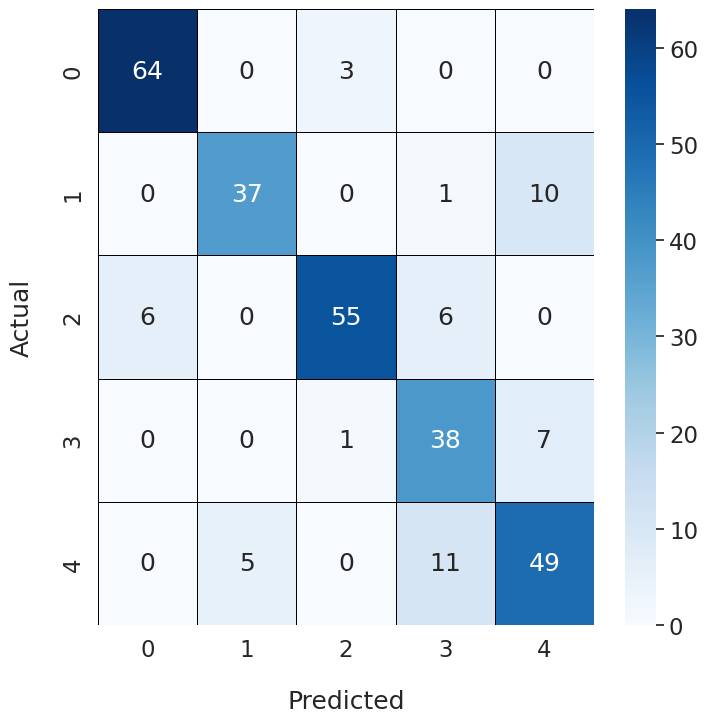

Epoch Training Time: 1806.90 seconds
Test set: Average loss: 0.4239, Accuracy: 276/323 (85.45%), F1 Score: 0.8536

Fold 2
-------
Early stopping at epoch 180 due to no improvement in validation loss.


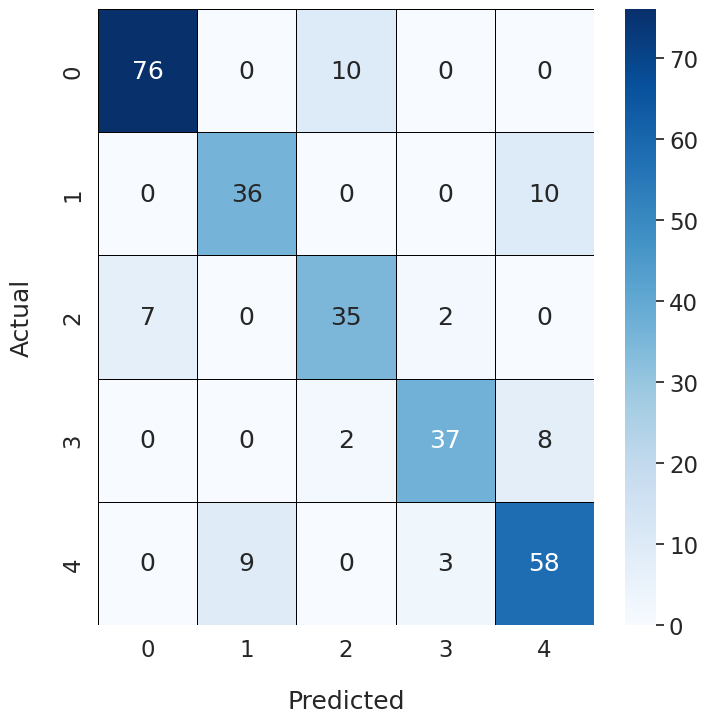

Epoch Training Time: 1661.48 seconds
Test set: Average loss: 0.4987, Accuracy: 257/323 (79.57%), F1 Score: 0.7949

Fold 3
-------
Early stopping at epoch 147 due to no improvement in validation loss.


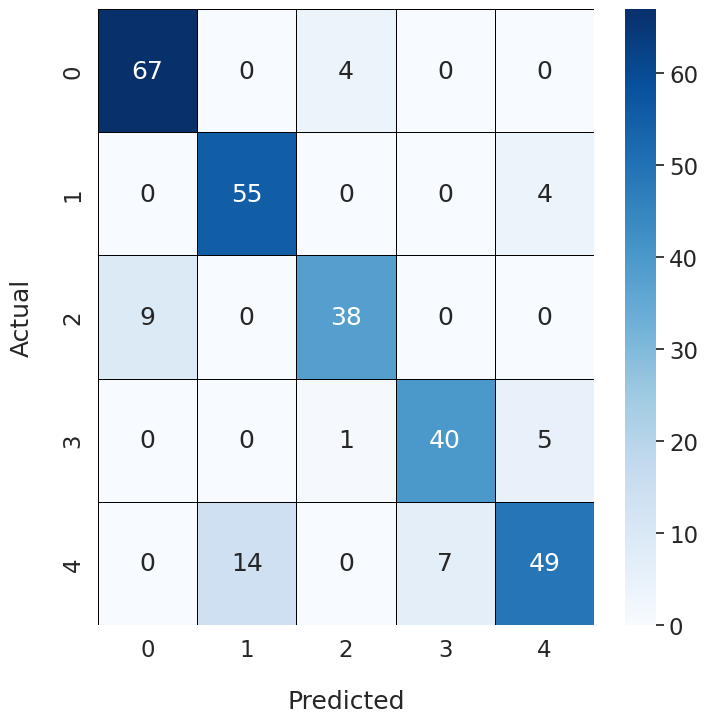

Epoch Training Time: 1356.97 seconds
Test set: Average loss: 0.4646, Accuracy: 256/323 (79.26%), F1 Score: 0.7907

Fold 4
-------
Early stopping at epoch 169 due to no improvement in validation loss.


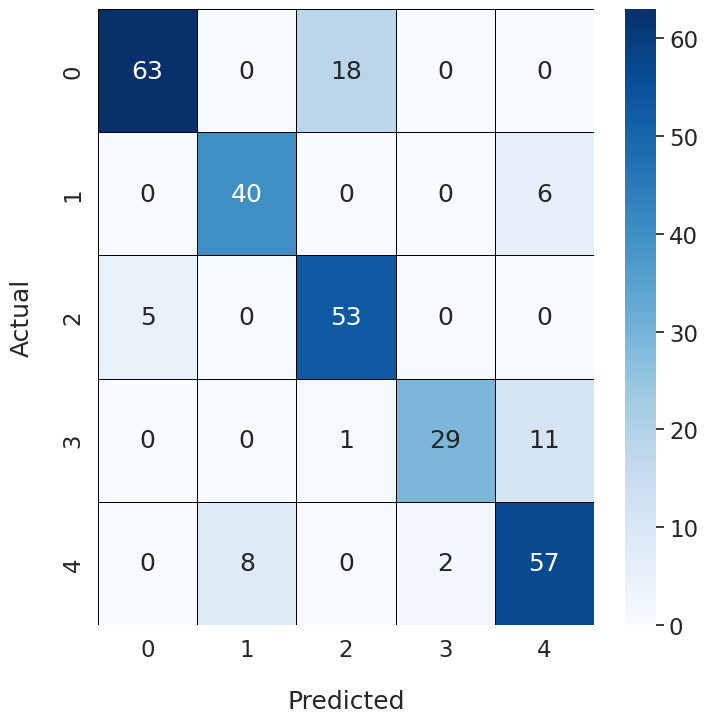

Epoch Training Time: 1639.43 seconds
Test set: Average loss: 0.4389, Accuracy: 269/323 (83.28%), F1 Score: 0.8324

Fold 5
-------
Early stopping at epoch 156 due to no improvement in validation loss.


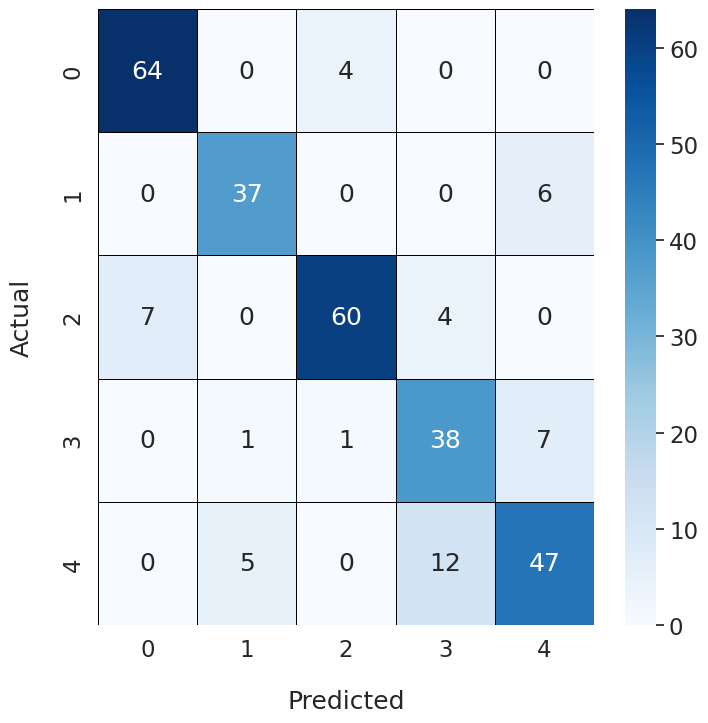

Epoch Training Time: 1402.64 seconds
Test set: Average loss: 0.4317, Accuracy: 274/323 (84.83%), F1 Score: 0.8469

Fold 6
-------
Early stopping at epoch 184 due to no improvement in validation loss.


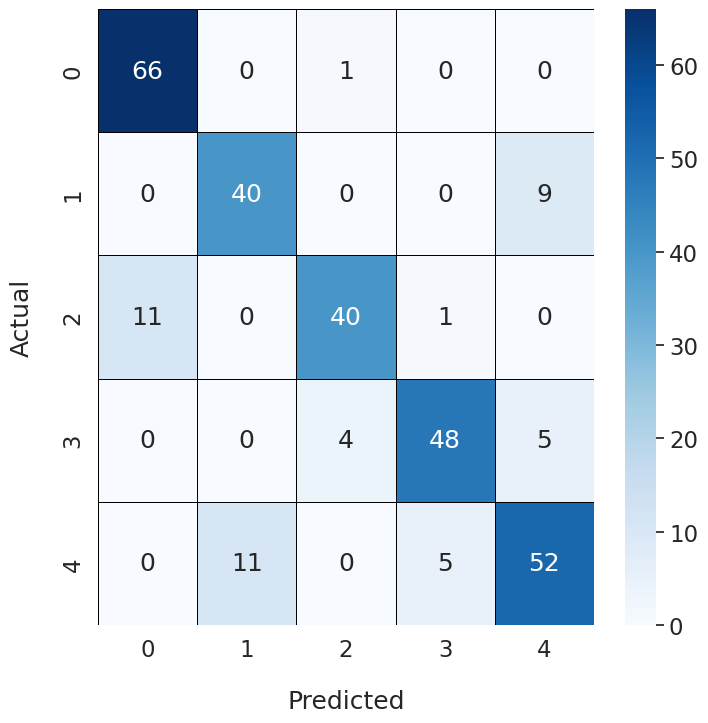

Epoch Training Time: 1932.96 seconds
Test set: Average loss: 0.5251, Accuracy: 262/323 (81.11%), F1 Score: 0.8113

Fold 7
-------
Early stopping at epoch 160 due to no improvement in validation loss.


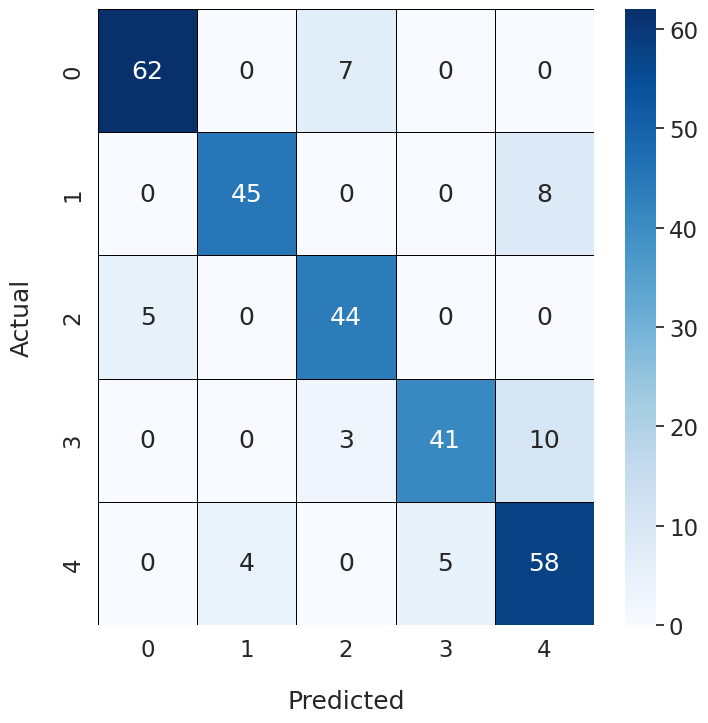

Epoch Training Time: 1532.37 seconds
Test set: Average loss: 0.4390, Accuracy: 270/323 (83.59%), F1 Score: 0.8340

Fold 8
-------
Early stopping at epoch 188 due to no improvement in validation loss.


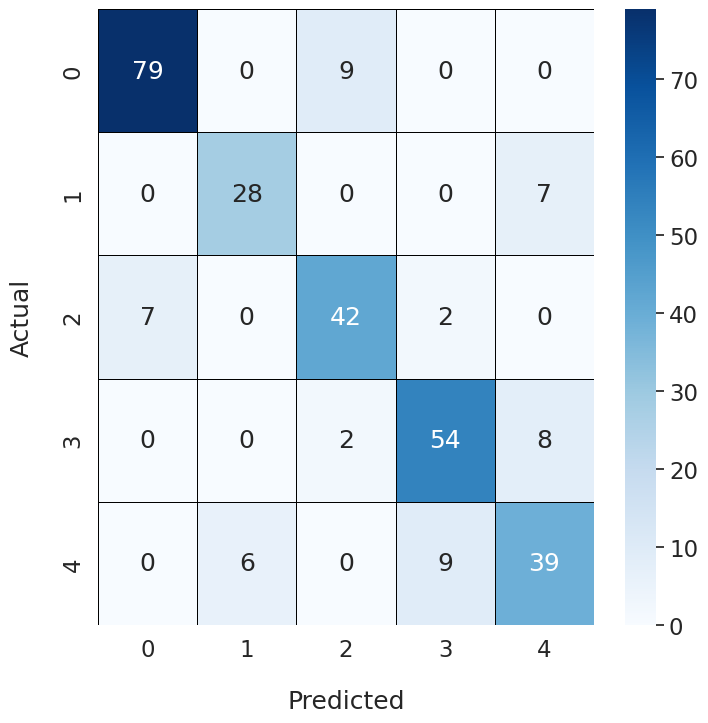

Epoch Training Time: 1855.51 seconds
Test set: Average loss: 0.4833, Accuracy: 267/323 (82.66%), F1 Score: 0.8252

Fold 9
-------
Early stopping at epoch 170 due to no improvement in validation loss.


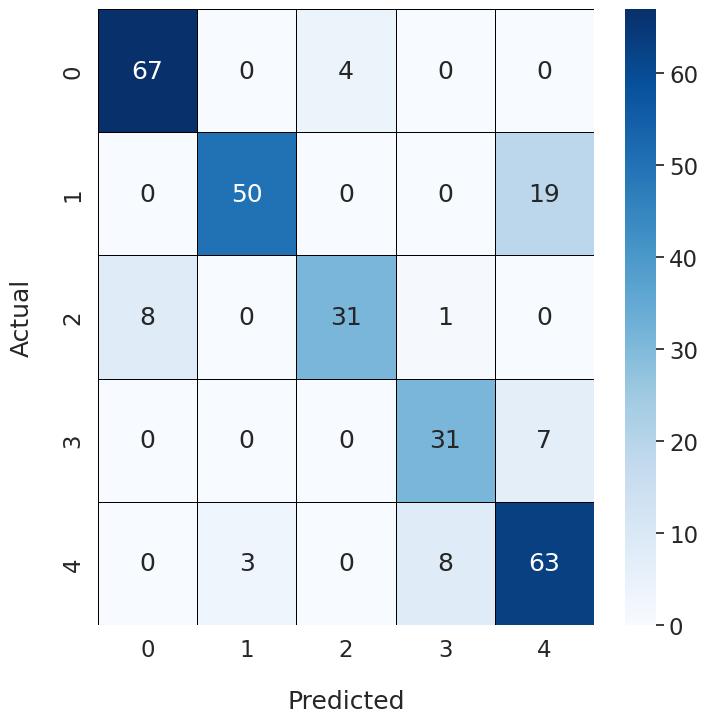

Epoch Training Time: 1682.81 seconds
Test set: Average loss: 0.4507, Accuracy: 272/323 (84.21%), F1 Score: 0.8411

Fold 10
-------
Early stopping at epoch 169 due to no improvement in validation loss.


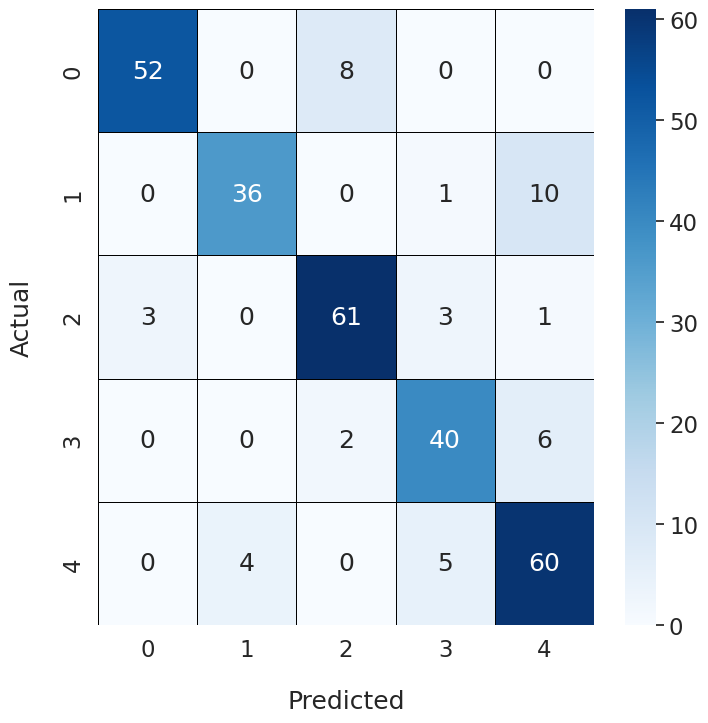

Epoch Training Time: 1857.08 seconds
Test set: Average loss: 0.4499, Accuracy: 271/323 (83.90%), F1 Score: 0.8372


Total training time for 10 folds: 16728.14 seconds


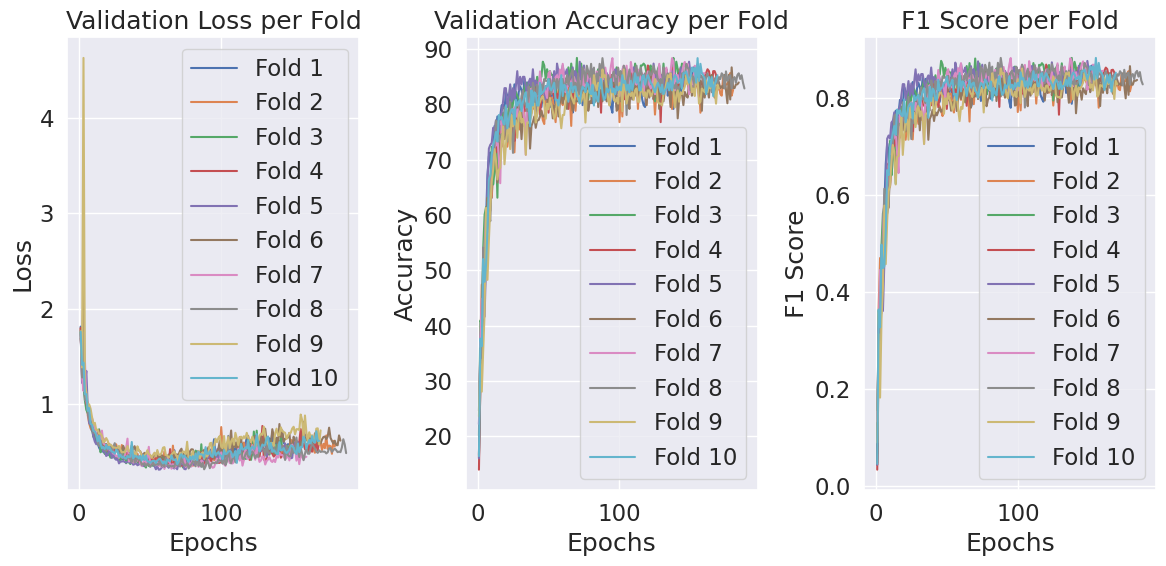

Maximum Fold Accuracy = 85.44891640866874
Maximum Fold F1 Score = 0.8536218156557954
Average Fold Accuracy = 82.78637770897834
Average Fold F1 Score = 0.8267467035292816


In [5]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "/home/gpu1/Desktop/rut_ws/Restnet101/result_Restnet/noSE"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/noSE/best_noSE.pth"
os.makedirs("./model_Restnet/noSE", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_noSE.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []

   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet(ResidualBlock, [3, 4, 23, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
          
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"noSE_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])

    all_folds_val_loss.append(epoch_val_loss.copy())
    all_folds_val_acc.append(epoch_val_acc.copy())
    all_folds_f1.append(epochs_f1_score.copy())

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet(ResidualBlock, [3, 4, 23, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout_

In [6]:
clear_all_memory()

Memory cleared and environment reset!


SE(avg original) + Restnet101-------------------------------------------------------------------------------------------

In [7]:
import import_ipynb
from starter_restnet import *

In [8]:
class SE_Block(nn.Module):
    "credits: https://github.com/moskomule/senet.pytorch/blob/master/senet/se_module.py#L4"
    def __init__(self, c, r=8):
        super().__init__()
        self.squeeze = nn.AdaptiveAvgPool2d(1)
        self.excitation = nn.Sequential(
            nn.Linear(c, c // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(c // r, c, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        bs, c, _, _ = x.shape
        y = self.squeeze(x).view(bs, c)
        y = self.excitation(y).view(bs, c, 1, 1)
        return x * y.expand_as(x)

In [9]:
class ResidualBlock_SEavg(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=8):
            super(ResidualBlock_SEavg, self).__init__()
            
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 1, stride = stride, padding = 0),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv3 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels*4, kernel_size = 1, stride = 1, padding = 0),
                            nn.BatchNorm2d(out_channels*4))
                           
            
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels

            self.se = SE_Block(out_channels*4, r)

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            out = self.conv3(out)

            out = self.se(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_SEavg(nn.Module):
    
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_SEavg, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
            self.fc = nn.Linear(2048, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes*4:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes*4, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes*4),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes*4
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.avgpool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [10]:
all_folds_val_loss = []
all_folds_val_acc = []
all_folds_f1 = []
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 10.02 GMac
Model Params: 52.05 M
Early stopping at epoch 138 due to no improvement in validation loss.


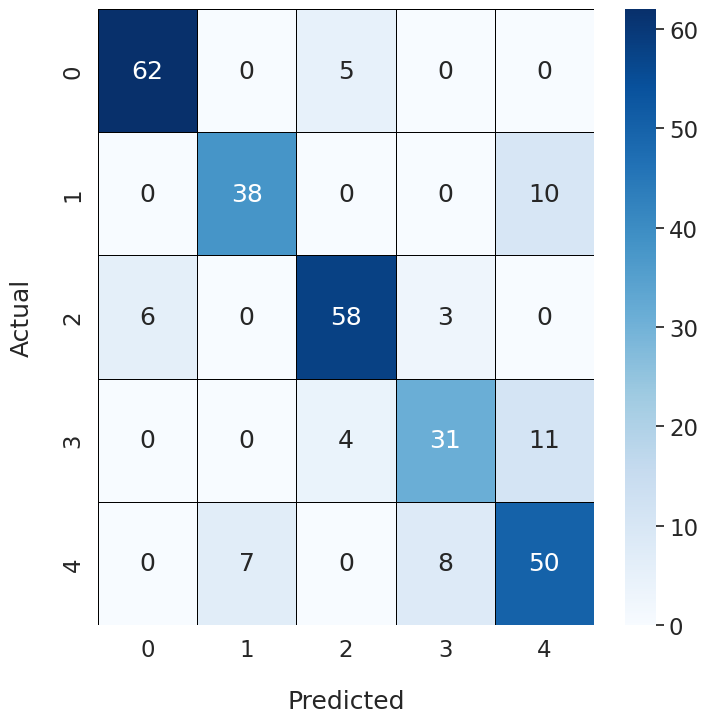

Epoch Training Time: 1444.27 seconds
Test set: Average loss: 0.4637, Accuracy: 260/323 (80.50%), F1 Score: 0.8031

Fold 2
-------
Early stopping at epoch 170 due to no improvement in validation loss.


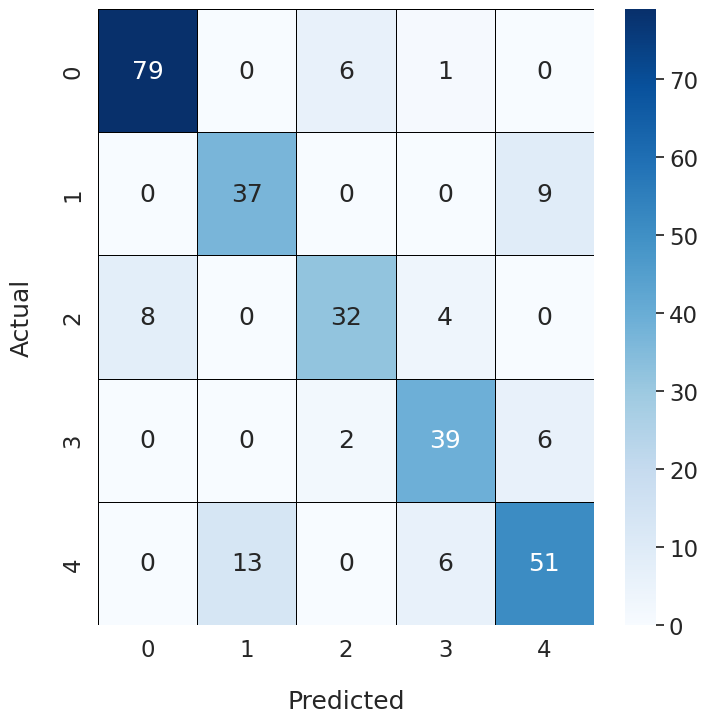

Epoch Training Time: 1698.43 seconds
Test set: Average loss: 0.4642, Accuracy: 268/323 (82.97%), F1 Score: 0.8291

Fold 3
-------
Early stopping at epoch 167 due to no improvement in validation loss.


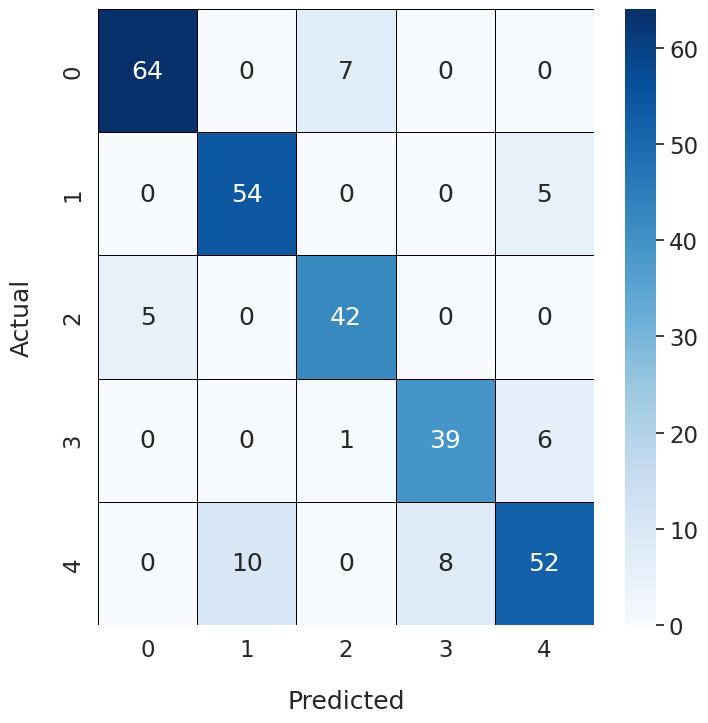

Epoch Training Time: 1798.75 seconds
Test set: Average loss: 0.4086, Accuracy: 266/323 (82.35%), F1 Score: 0.8238

Fold 4
-------
Early stopping at epoch 197 due to no improvement in validation loss.


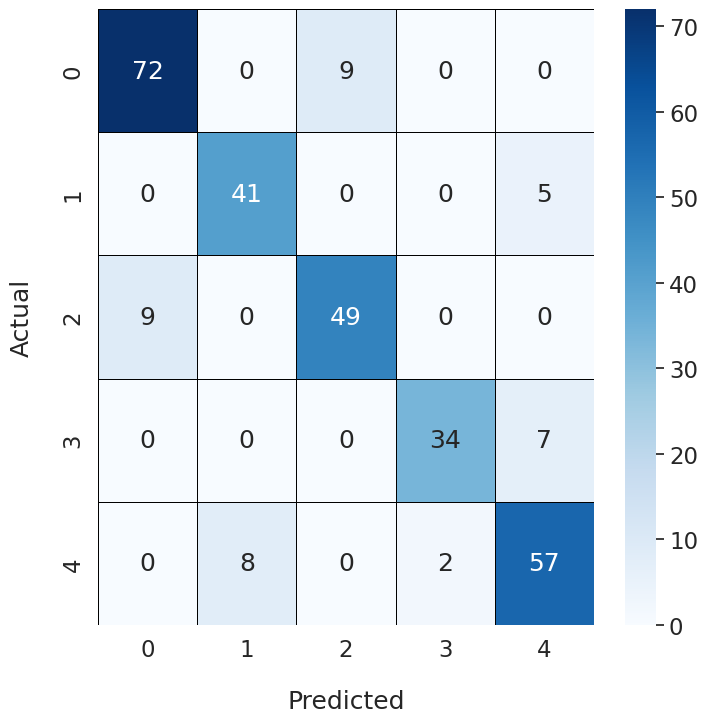

Epoch Training Time: 2203.88 seconds
Test set: Average loss: 0.5418, Accuracy: 266/323 (82.35%), F1 Score: 0.8228

Fold 5
-------
Early stopping at epoch 158 due to no improvement in validation loss.


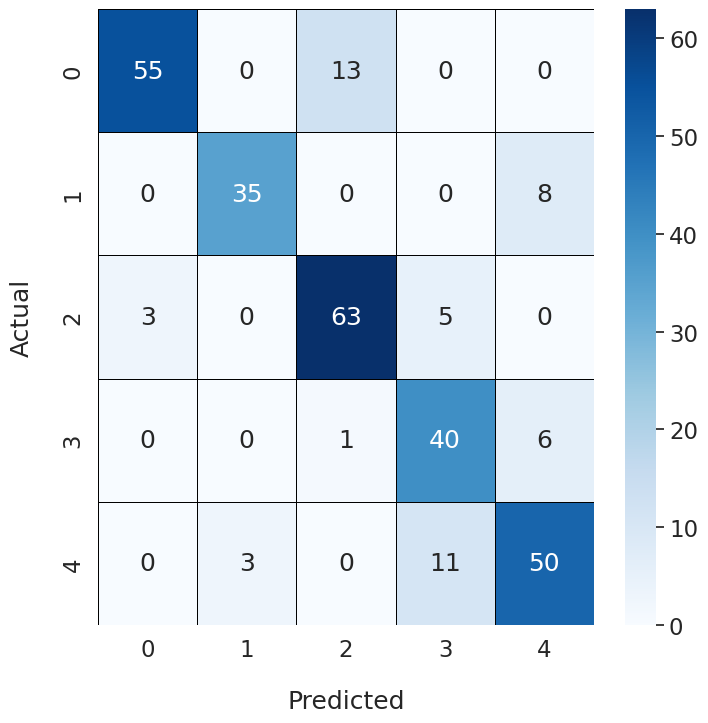

Epoch Training Time: 1693.58 seconds
Test set: Average loss: 0.4571, Accuracy: 262/323 (81.11%), F1 Score: 0.8090

Fold 6
-------
Early stopping at epoch 168 due to no improvement in validation loss.


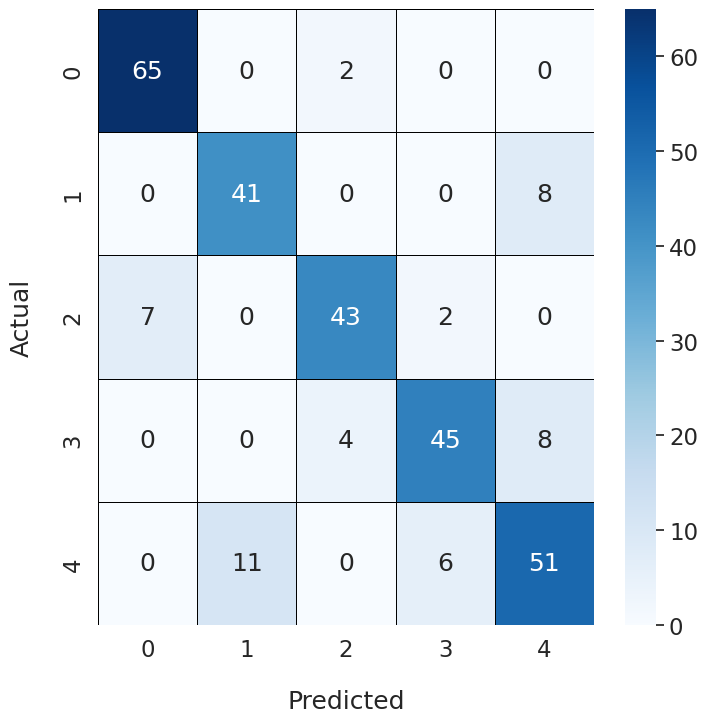

Epoch Training Time: 1779.33 seconds
Test set: Average loss: 0.4468, Accuracy: 264/323 (81.73%), F1 Score: 0.8180

Fold 7
-------
Early stopping at epoch 169 due to no improvement in validation loss.


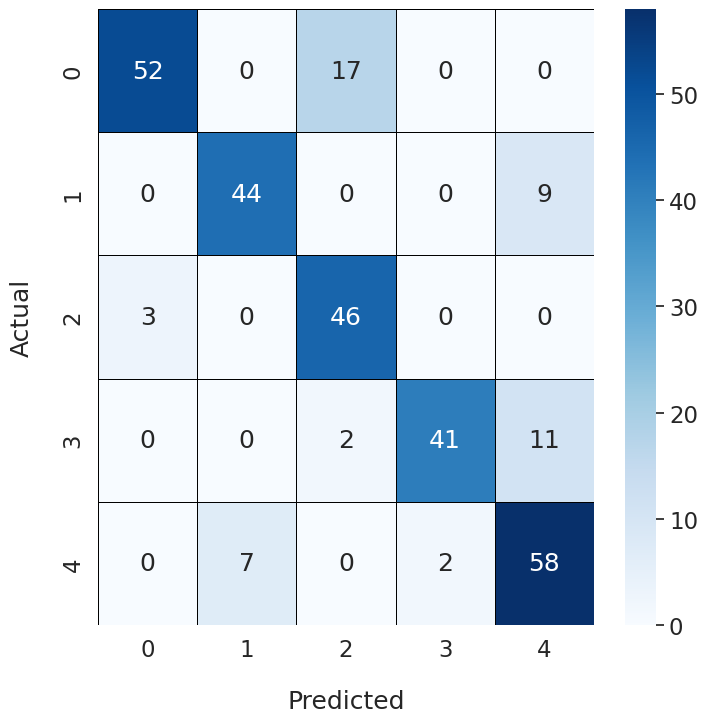

Epoch Training Time: 1631.16 seconds
Test set: Average loss: 0.4463, Accuracy: 267/323 (82.66%), F1 Score: 0.8249

Fold 8
-------
Early stopping at epoch 163 due to no improvement in validation loss.


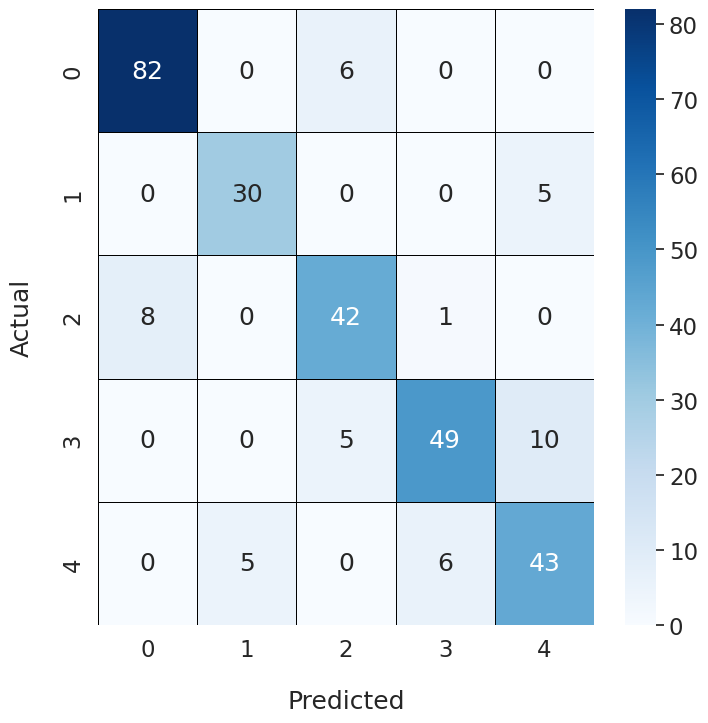

Epoch Training Time: 1867.25 seconds
Test set: Average loss: 0.5000, Accuracy: 269/323 (83.28%), F1 Score: 0.8322

Fold 9
-------
Early stopping at epoch 164 due to no improvement in validation loss.


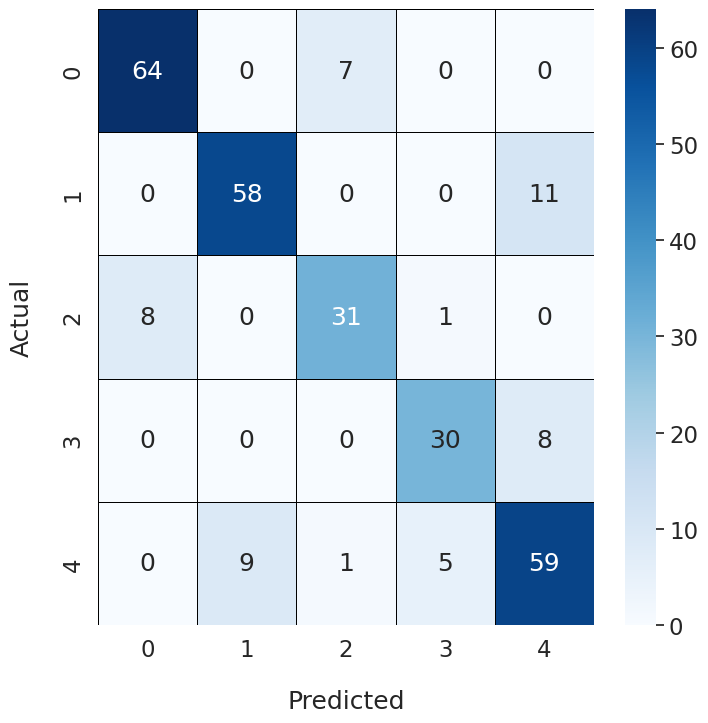

Epoch Training Time: 1731.32 seconds
Test set: Average loss: 0.4065, Accuracy: 274/323 (84.83%), F1 Score: 0.8477

Fold 10
-------
Early stopping at epoch 158 due to no improvement in validation loss.


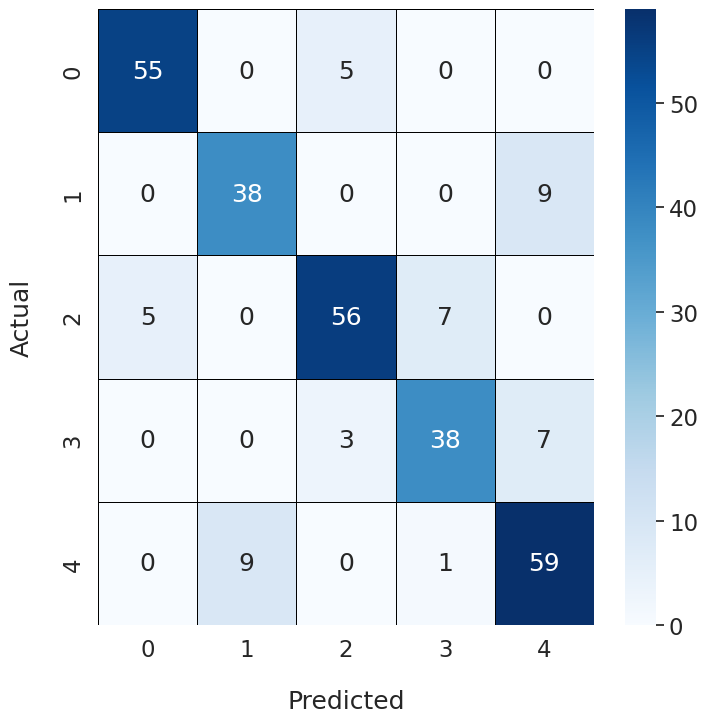

Epoch Training Time: 1682.65 seconds
Test set: Average loss: 0.4061, Accuracy: 270/323 (83.59%), F1 Score: 0.8357


Total training time for 10 folds: 17530.62 seconds


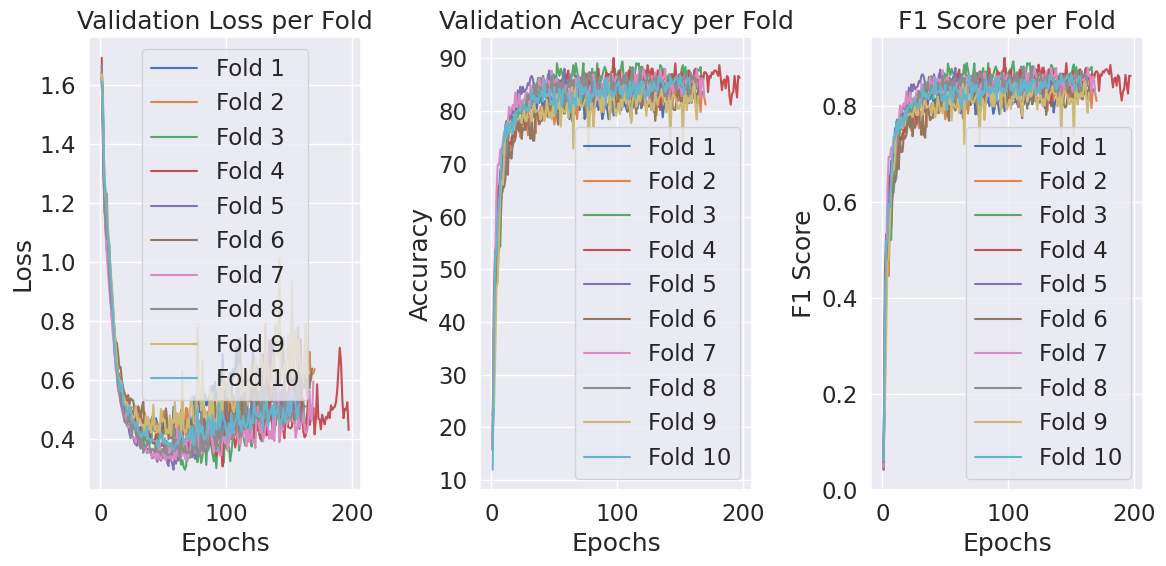

Maximum Fold Accuracy = 84.82972136222911
Maximum Fold F1 Score = 0.847688828011506
Average Fold Accuracy = 82.53869969040248
Average Fold F1 Score = 0.8246272695570207


In [11]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "/home/gpu1/Desktop/rut_ws/Restnet101/result_Restnet/SE_avg"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/SE_avg/best_SE_avg.pth"
os.makedirs("./model_Restnet/SE_avg", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_SEavg.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_SEavg(ResidualBlock_SEavg, [3, 4, 23, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
          
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEavg_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])

    all_folds_val_loss.append(epoch_val_loss.copy())
    all_folds_val_acc.append(epoch_val_acc.copy())
    all_folds_f1.append(epochs_f1_score.copy())
            
    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet_SEavg(ResidualBlock_SEavg, [3, 4, 23, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout_

In [12]:
clear_all_memory()

Memory cleared and environment reset!


SE(max)+VGG16----------------------------------------------------------------------------------------------------------

In [13]:
import import_ipynb
from starter_restnet import *

In [14]:
class SE_Block_max(nn.Module):
    "credits: https://github.com/moskomule/senet.pytorch/blob/master/senet/se_module.py#L4"
    def __init__(self, c, r=8):
        super().__init__()
        self.squeeze = nn.AdaptiveMaxPool2d(1)
        self.excitation = nn.Sequential(
            nn.Linear(c, c // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(c // r, c, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        bs, c, _, _ = x.shape
        y = self.squeeze(x).view(bs, c)
        y = self.excitation(y).view(bs, c, 1, 1)
        return x * y.expand_as(x)

In [15]:
class ResidualBlock_SEmax(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=8):
            super(ResidualBlock_SEmax, self).__init__()
            
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 1, stride = stride, padding = 0),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv3 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels*4, kernel_size = 1, stride = 1, padding = 0),
                            nn.BatchNorm2d(out_channels*4))
                           
            
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels

            self.se = SE_Block_max(out_channels*4, r)

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            out = self.conv3(out)

            out = self.se(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_SEmax(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_SEmax, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
            self.fc = nn.Linear(2048, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes*4:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes*4, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes*4),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes*4
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.avgpool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [16]:
all_folds_val_loss = [] 
all_folds_val_acc = [] 
all_folds_f1 = []
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 10.02 GMac
Model Params: 52.05 M
Early stopping at epoch 156 due to no improvement in validation loss.


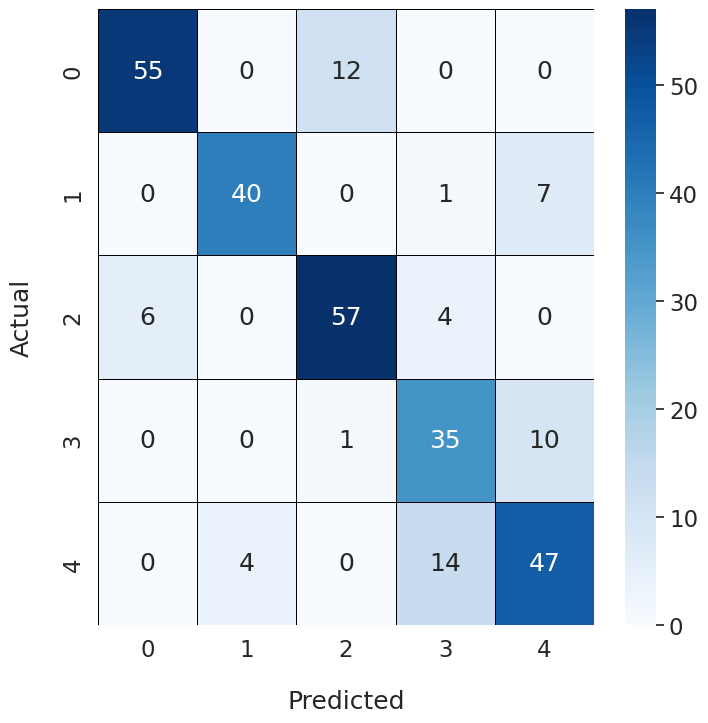

Epoch Training Time: 1805.47 seconds
Test set: Average loss: 0.4457, Accuracy: 268/323 (82.97%), F1 Score: 0.8298

Fold 2
-------
Early stopping at epoch 177 due to no improvement in validation loss.


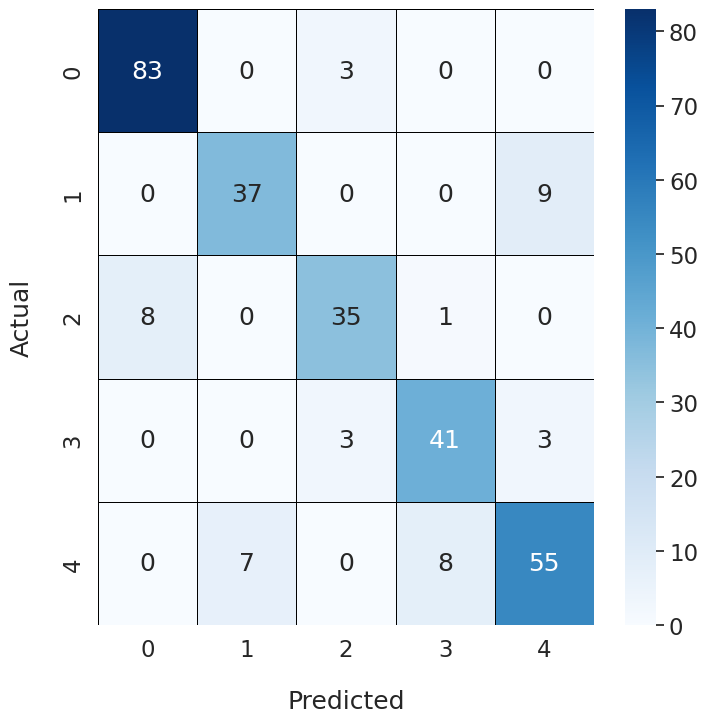

Epoch Training Time: 2214.63 seconds
Test set: Average loss: 0.4948, Accuracy: 263/323 (81.42%), F1 Score: 0.8126

Fold 3
-------
Early stopping at epoch 162 due to no improvement in validation loss.


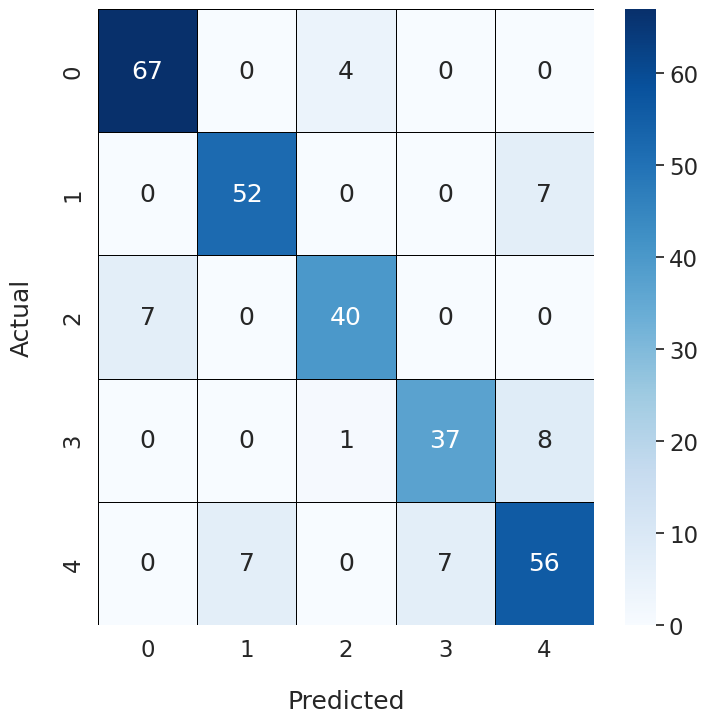

Epoch Training Time: 1985.73 seconds
Test set: Average loss: 0.4176, Accuracy: 267/323 (82.66%), F1 Score: 0.8258

Fold 4
-------
Early stopping at epoch 158 due to no improvement in validation loss.


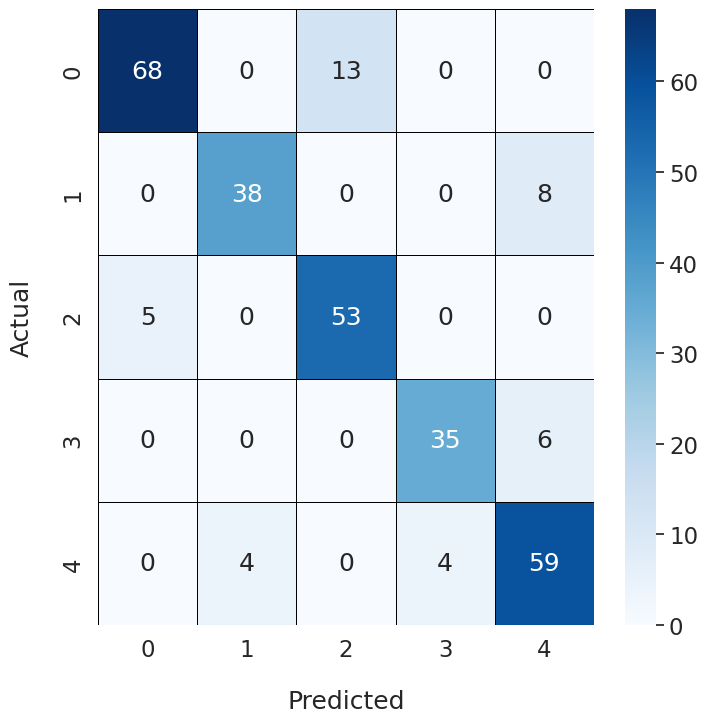

Epoch Training Time: 2064.39 seconds
Test set: Average loss: 0.4443, Accuracy: 265/323 (82.04%), F1 Score: 0.8200

Fold 5
-------
Early stopping at epoch 157 due to no improvement in validation loss.


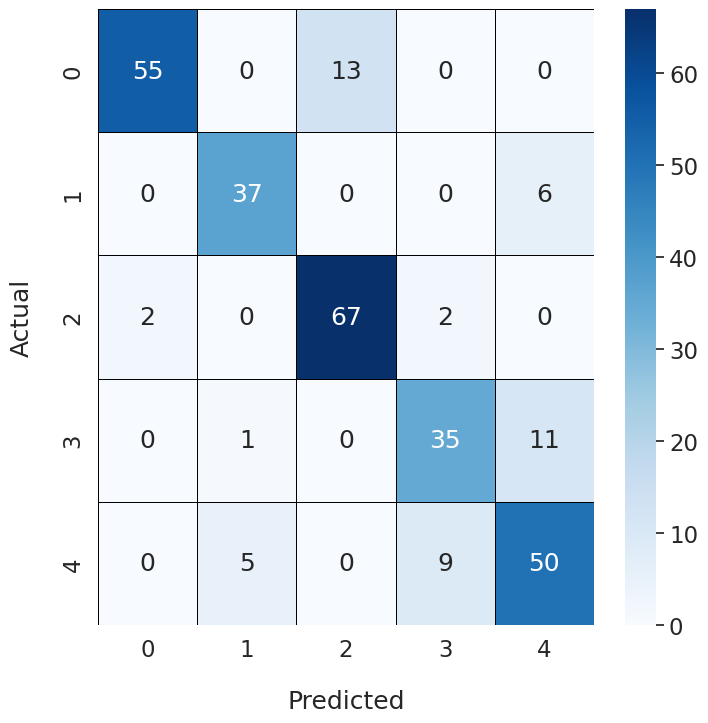

Epoch Training Time: 1839.44 seconds
Test set: Average loss: 0.3985, Accuracy: 274/323 (84.83%), F1 Score: 0.8472

Fold 6
-------
Early stopping at epoch 162 due to no improvement in validation loss.


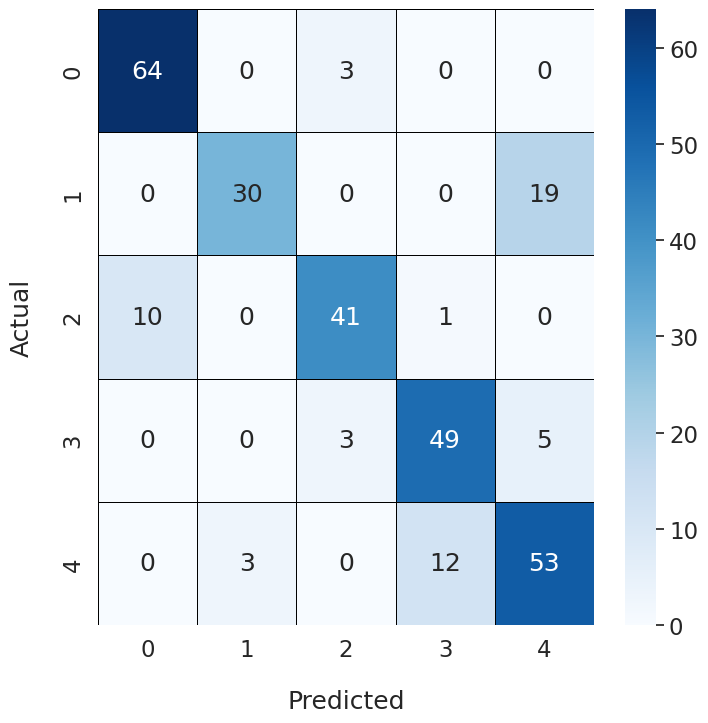

Epoch Training Time: 2011.36 seconds
Test set: Average loss: 0.4035, Accuracy: 274/323 (84.83%), F1 Score: 0.8469

Fold 7
-------
Early stopping at epoch 162 due to no improvement in validation loss.


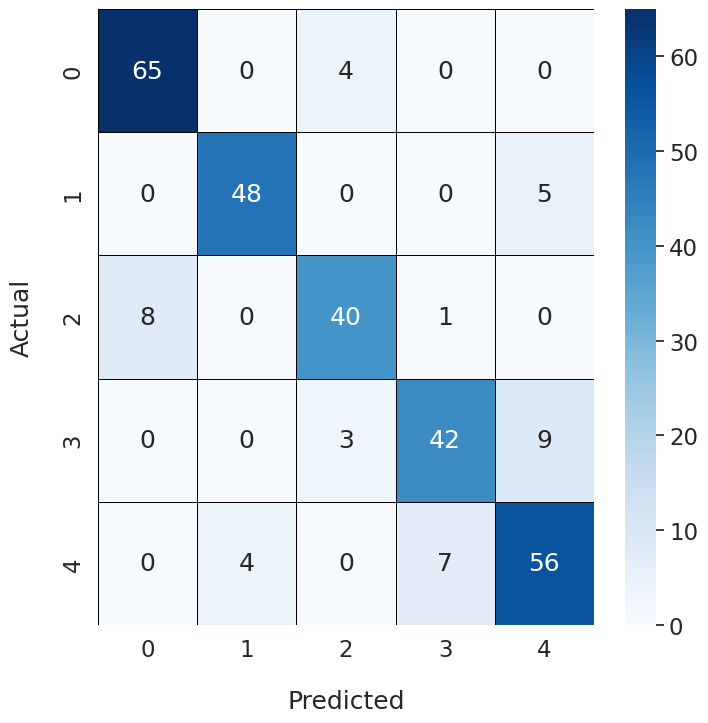

Epoch Training Time: 1829.13 seconds
Test set: Average loss: 0.4212, Accuracy: 269/323 (83.28%), F1 Score: 0.8313

Fold 8
-------
Early stopping at epoch 152 due to no improvement in validation loss.


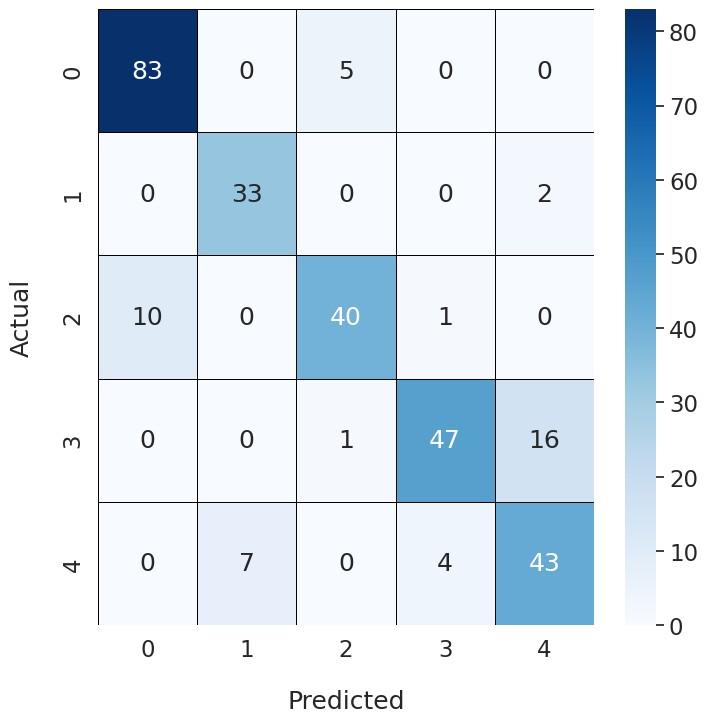

Epoch Training Time: 1802.89 seconds
Test set: Average loss: 0.4316, Accuracy: 269/323 (83.28%), F1 Score: 0.8298

Fold 9
-------
Early stopping at epoch 157 due to no improvement in validation loss.


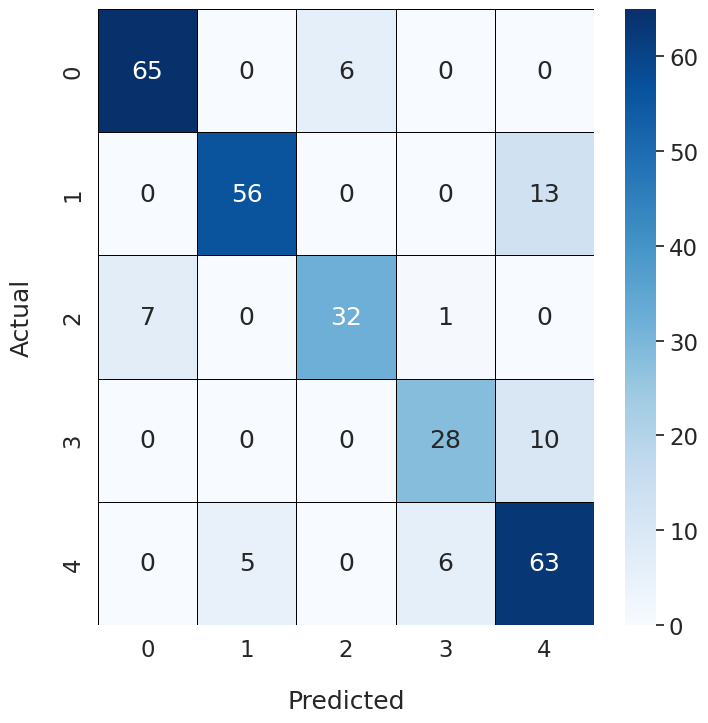

Epoch Training Time: 1919.18 seconds
Test set: Average loss: 0.4038, Accuracy: 272/323 (84.21%), F1 Score: 0.8402

Fold 10
-------
Early stopping at epoch 177 due to no improvement in validation loss.


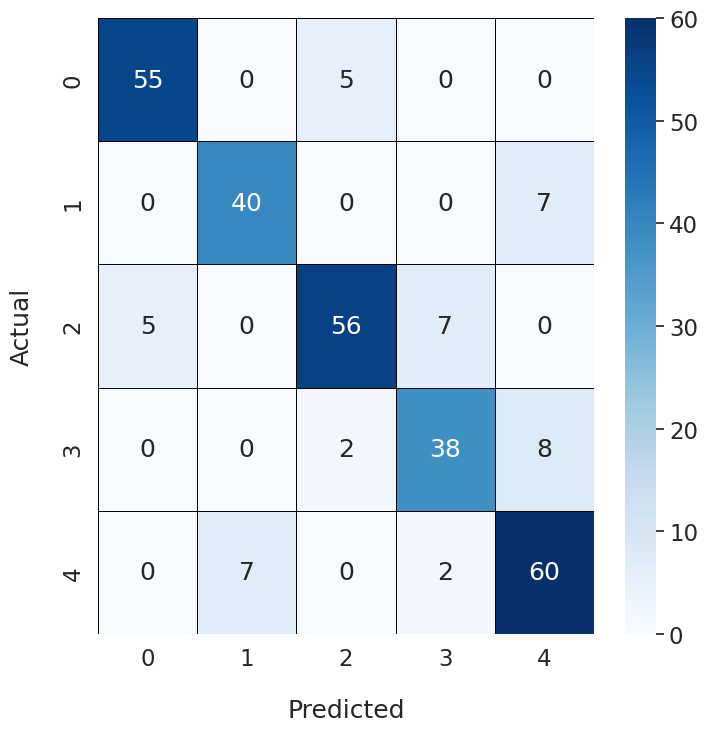

Epoch Training Time: 2242.14 seconds
Test set: Average loss: 0.4964, Accuracy: 261/323 (80.80%), F1 Score: 0.8089


Total training time for 10 folds: 19714.37 seconds


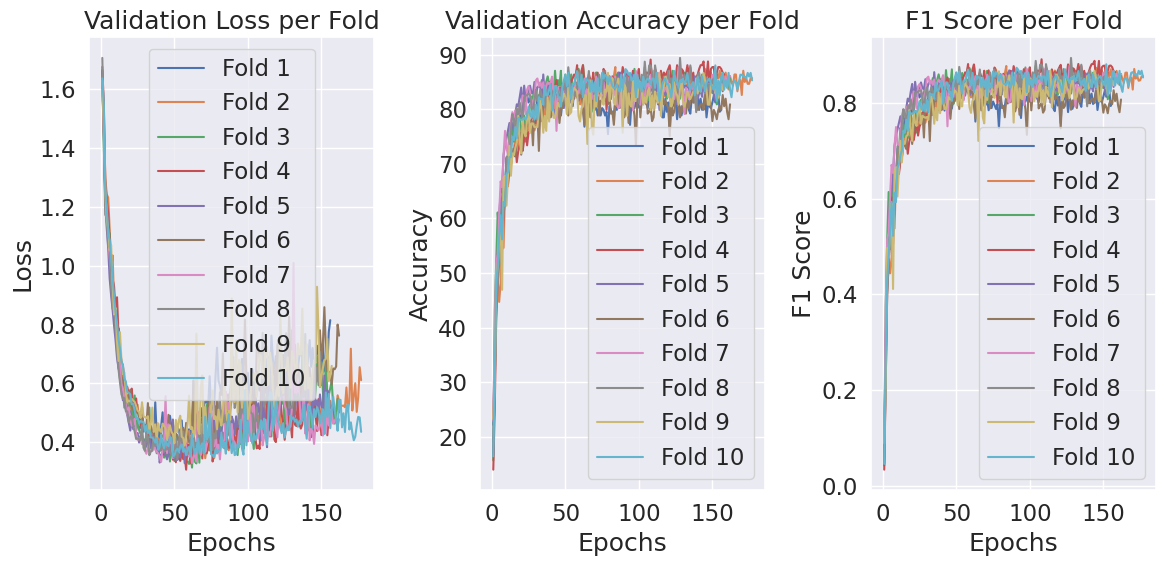

Maximum Fold Accuracy = 84.82972136222911
Maximum Fold F1 Score = 0.8471988807941545
Average Fold Accuracy = 83.03405572755418
Average Fold F1 Score = 0.8292501753805765


In [17]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "/home/gpu1/Desktop/rut_ws/Restnet101/result_Restnet/SE_max"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/SE_max/best_SE_max.pth"
os.makedirs("./model_Restnet/SE_max", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_SEmax.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []

   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_SEmax(ResidualBlock_SEmax, [3, 4, 23, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
          
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEmax_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------
    

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    best_model = ResNet_SEmax(ResidualBlock_SEmax, [3, 4, 23, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
    

max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [18]:
clear_all_memory()

Memory cleared and environment reset!


SE mixed pool + Restnet101---------------------------------------------------------------------------------------

In [19]:
from Mixedpool05 import mixedPool

alpha = 0.5


In [20]:
import import_ipynb
from starter_restnet import *

In [21]:
class SE_Block_mix(nn.Module):
    "credits: https://github.com/moskomule/senet.pytorch/blob/master/senet/se_module.py#L4"
    def __init__(self, c, r=8):
        super().__init__()
        self.squeeze = mixedPool()
        self.excitation = nn.Sequential(
            nn.Linear(c, c // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(c // r, c, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        bs, c, _, _ = x.shape
        y = self.squeeze(x).view(bs, c)
        y = self.excitation(y).view(bs, c, 1, 1)
        return x * y.expand_as(x)

In [22]:
class ResidualBlock_SEmix(nn.Module):
    
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=8):
            super(ResidualBlock_SEmix, self).__init__()
            
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 1, stride = stride, padding = 0),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv3 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels*4, kernel_size = 1, stride = 1, padding = 0),
                            nn.BatchNorm2d(out_channels*4))
                           
            
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels

            self.se = SE_Block_mix(out_channels*4, r)

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            out = self.conv3(out)

            out = self.se(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_SEmix(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_SEmix, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
            self.fc = nn.Linear(2048, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes*4:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes*4, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes*4),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes*4
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.avgpool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [23]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 10.02 GMac
Model Params: 52.05 M
Early stopping at epoch 157 due to no improvement in validation loss.


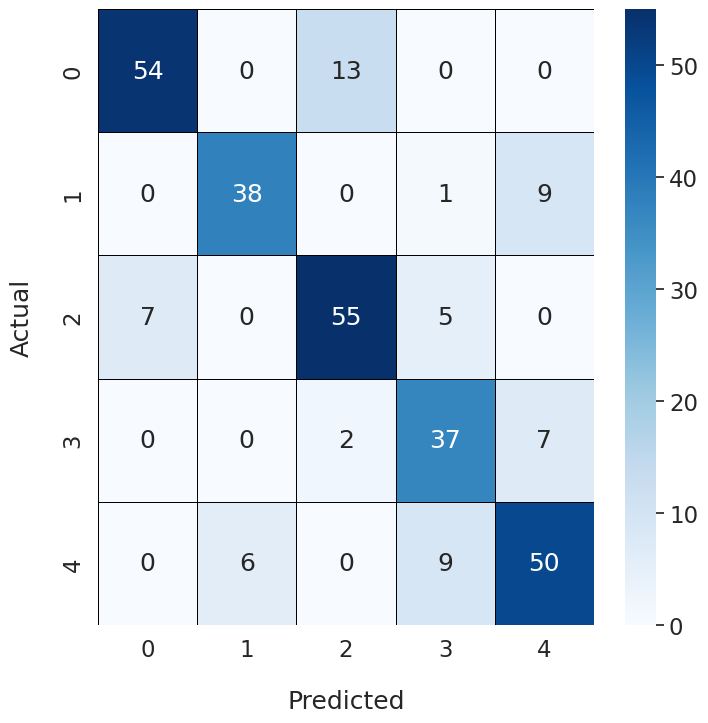

Epoch Training Time: 2015.38 seconds
Test set: Average loss: 0.4524, Accuracy: 262/323 (81.11%), F1 Score: 0.8095

Fold 2
-------
Early stopping at epoch 147 due to no improvement in validation loss.


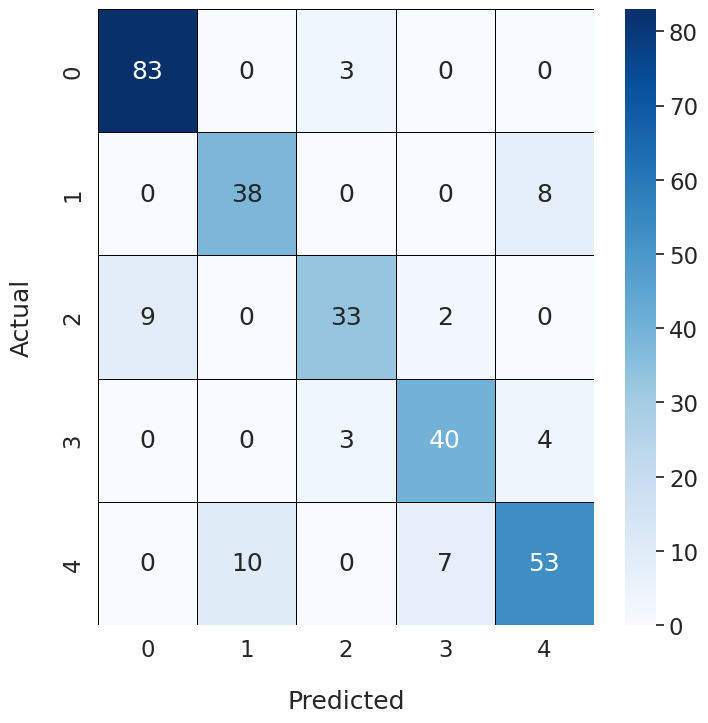

Epoch Training Time: 1703.70 seconds
Test set: Average loss: 0.4392, Accuracy: 265/323 (82.04%), F1 Score: 0.8188

Fold 3
-------
Early stopping at epoch 169 due to no improvement in validation loss.


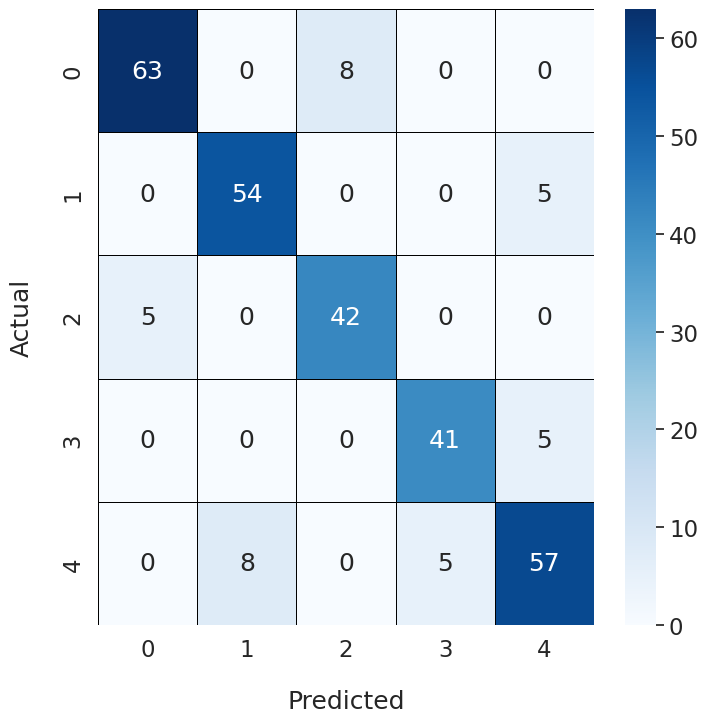

Epoch Training Time: 2097.74 seconds
Test set: Average loss: 0.4170, Accuracy: 268/323 (82.97%), F1 Score: 0.8291

Fold 4
-------
Early stopping at epoch 155 due to no improvement in validation loss.


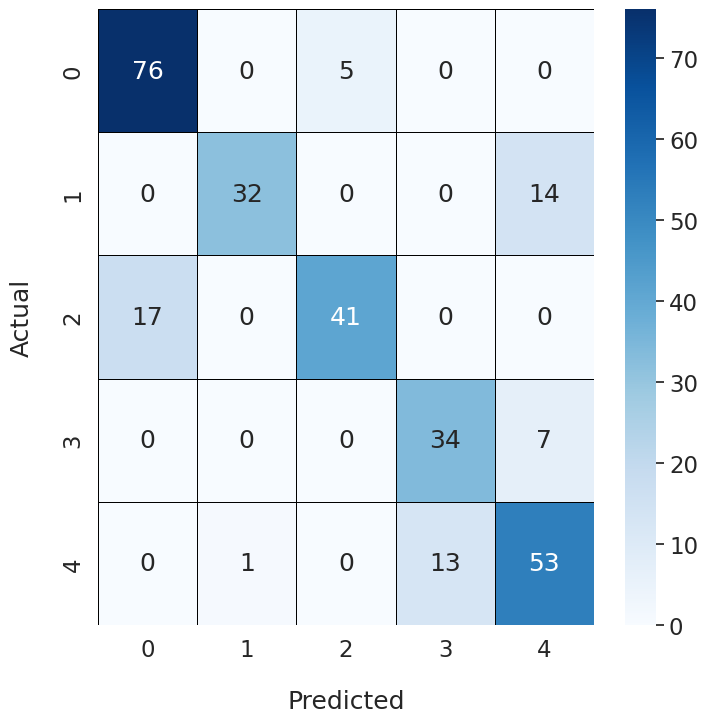

Epoch Training Time: 1982.09 seconds
Test set: Average loss: 0.4235, Accuracy: 270/323 (83.59%), F1 Score: 0.8347

Fold 5
-------
Early stopping at epoch 155 due to no improvement in validation loss.


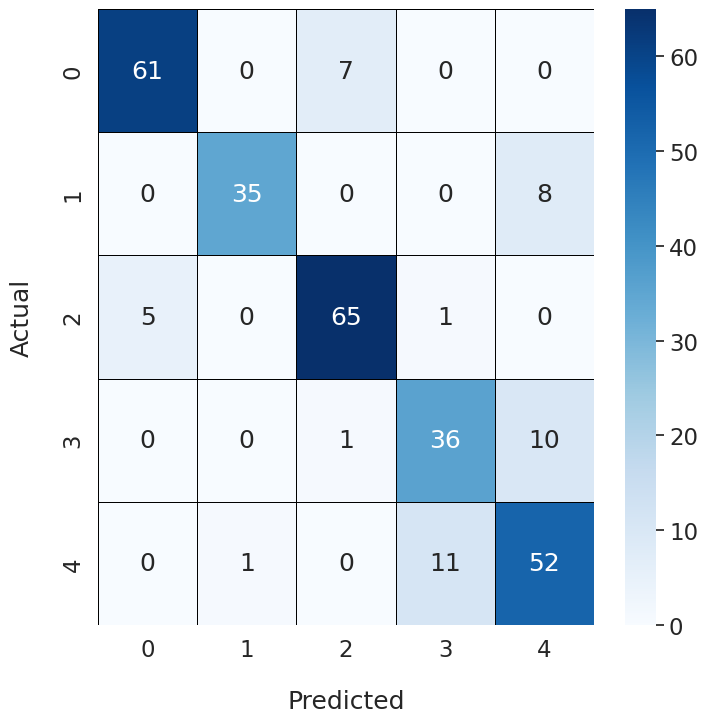

Epoch Training Time: 2173.54 seconds
Test set: Average loss: 0.4650, Accuracy: 266/323 (82.35%), F1 Score: 0.8204

Fold 6
-------
Early stopping at epoch 175 due to no improvement in validation loss.


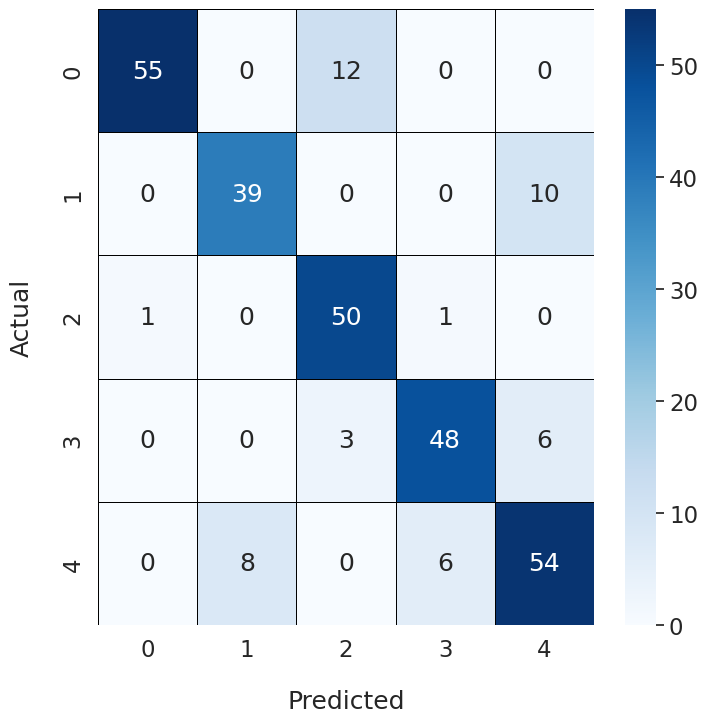

Epoch Training Time: 2354.20 seconds
Test set: Average loss: 0.4764, Accuracy: 271/323 (83.90%), F1 Score: 0.8380

Fold 7
-------
Early stopping at epoch 148 due to no improvement in validation loss.


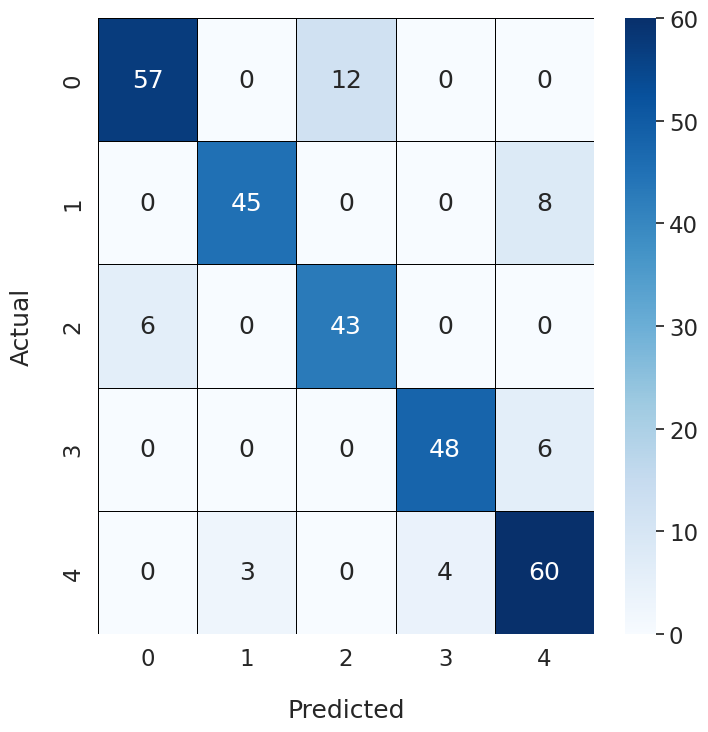

Epoch Training Time: 2148.13 seconds
Test set: Average loss: 0.4379, Accuracy: 267/323 (82.66%), F1 Score: 0.8237

Fold 8
-------
Early stopping at epoch 161 due to no improvement in validation loss.


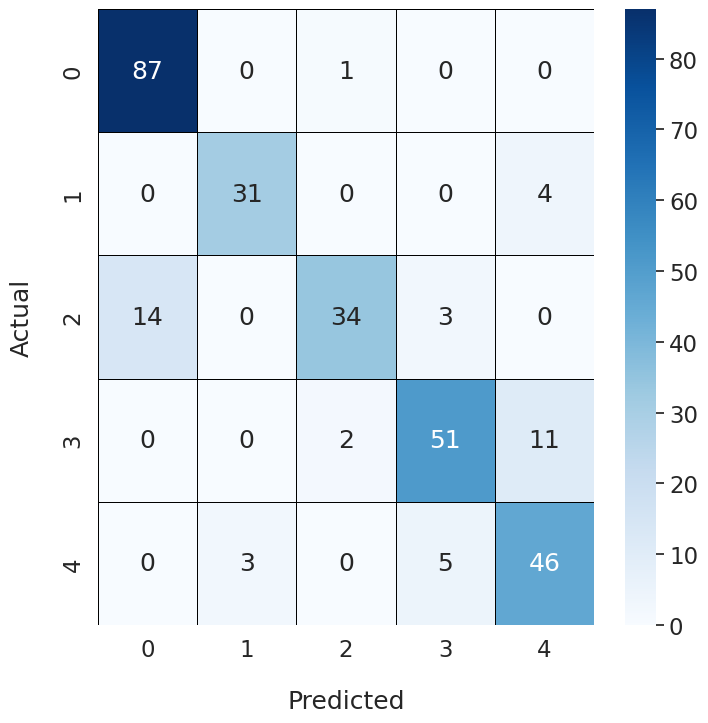

Epoch Training Time: 2206.31 seconds
Test set: Average loss: 0.4299, Accuracy: 270/323 (83.59%), F1 Score: 0.8353

Fold 9
-------
Early stopping at epoch 157 due to no improvement in validation loss.


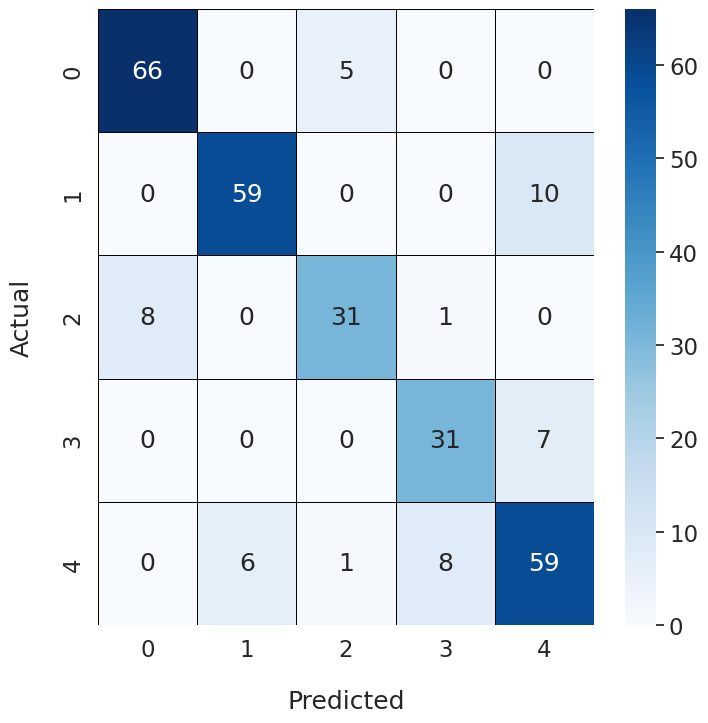

Epoch Training Time: 2132.24 seconds
Test set: Average loss: 0.3969, Accuracy: 271/323 (83.90%), F1 Score: 0.8372

Fold 10
-------
Early stopping at epoch 163 due to no improvement in validation loss.


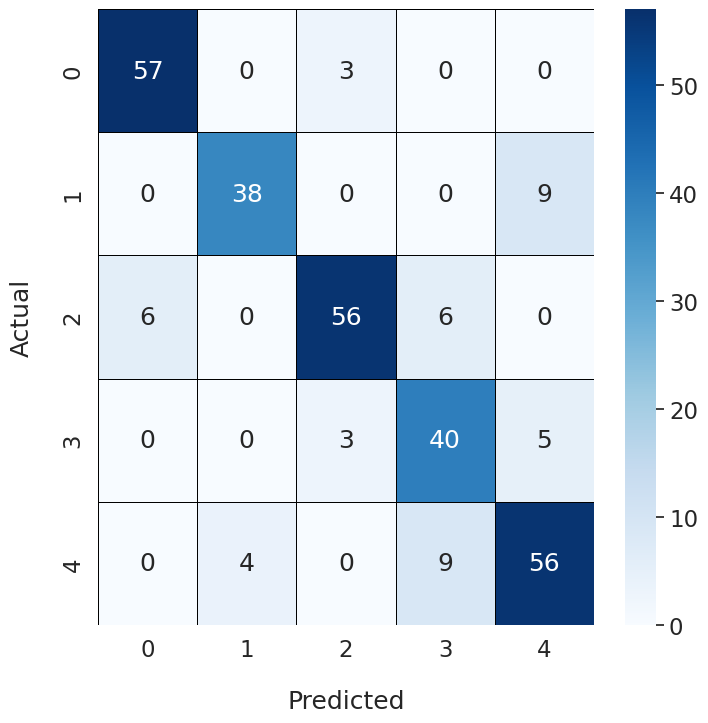

Epoch Training Time: 2036.11 seconds
Test set: Average loss: 0.4441, Accuracy: 266/323 (82.35%), F1 Score: 0.8220


Total training time for 10 folds: 20849.44 seconds


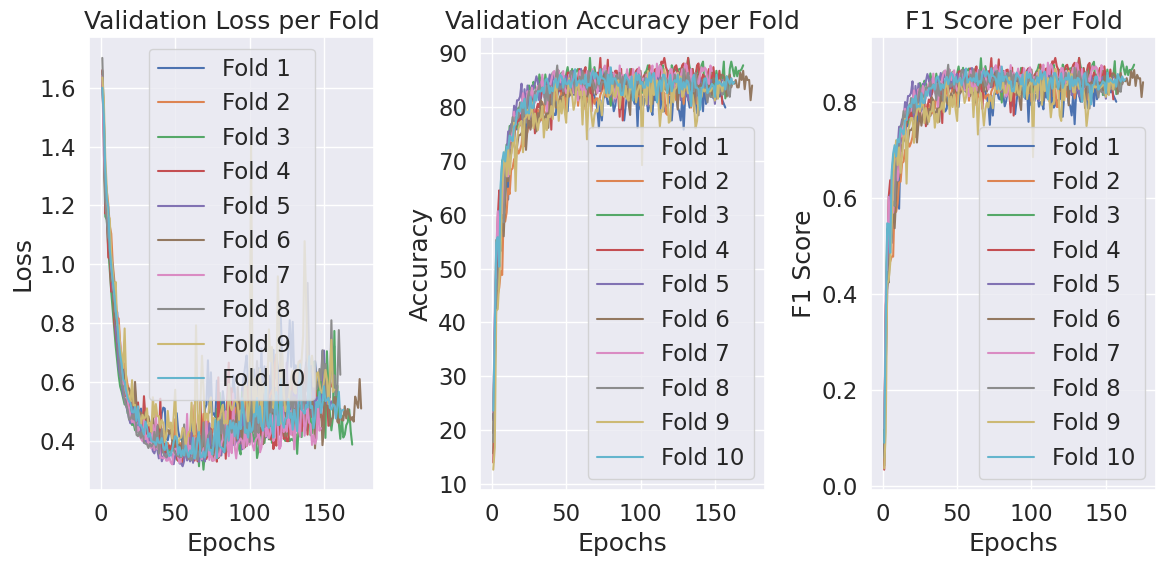

Maximum Fold Accuracy = 83.90092879256966
Maximum Fold F1 Score = 0.8380409649233201
Average Fold Accuracy = 82.84829721362229
Average Fold F1 Score = 0.8268851801472226


In [24]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "/home/gpu1/Desktop/rut_ws/Restnet101/result_Restnet/SE_mixed"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/SE_mix/best_SE_mix.pth"
os.makedirs("./model_Restnet/SE_mix", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_SEmix.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_SEmix(ResidualBlock_SEmix, [3, 4, 23, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
          
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEmix_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet_SEmix(ResidualBlock_SEmix, [3, 4, 23, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [25]:
clear_all_memory()

Memory cleared and environment reset!


SE fuzzy mixed pool + Restnet101---------------------------------------------------------------------------------------


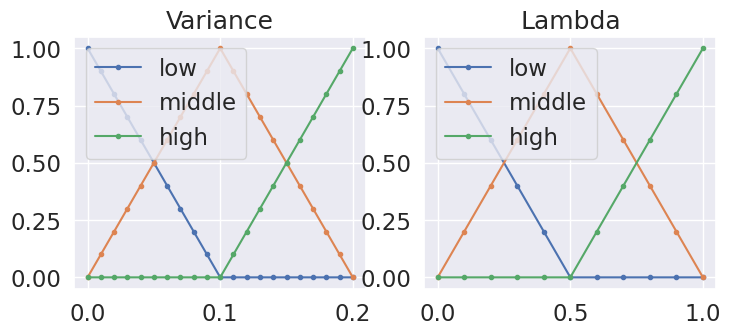

fuzzy_pool


In [26]:
from Mixedpool_fuzzy import mixedPool_fuzz

In [27]:
import import_ipynb
from starter_restnet import *
import sys

In [28]:
class SE_Block_fuzz(nn.Module):
    "credits: https://github.com/moskomule/senet.pytorch/blob/master/senet/se_module.py#L4"
    def __init__(self, c, r=8):
        super().__init__()
        self.squeeze = mixedPool_fuzz()
        self.excitation = nn.Sequential(
            nn.Linear(c, c // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(c // r, c, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        bs, c, _, _ = x.shape
        y = self.squeeze(x).view(bs, c)
        y = self.excitation(y).view(bs, c, 1, 1)
        return x * y.expand_as(x)

In [29]:
class ResidualBlock_SEfuzz(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=8):
            super(ResidualBlock_SEfuzz, self).__init__()
            
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 1, stride = stride, padding = 0),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv3 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels*4, kernel_size = 1, stride = 1, padding = 0),
                            nn.BatchNorm2d(out_channels*4))
                           
            
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels

            self.se = SE_Block_fuzz(out_channels*4, r)

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            out = self.conv3(out)

            out = self.se(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_SEfuzz(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_SEfuzz, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
            self.fc = nn.Linear(2048, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes*4:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes*4, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes*4),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes*4
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.avgpool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [30]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 10.02 GMac
Model Params: 52.05 M
Early stopping at epoch 145 due to no improvement in validation loss.


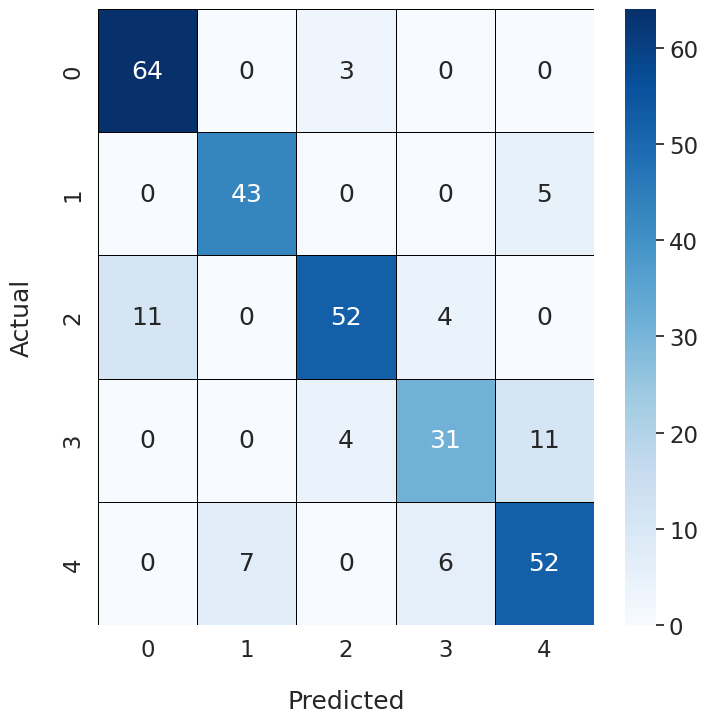

Epoch Training Time: 1872.98 seconds
Test set: Average loss: 0.4391, Accuracy: 263/323 (81.42%), F1 Score: 0.8146

Fold 2
-------
Early stopping at epoch 155 due to no improvement in validation loss.


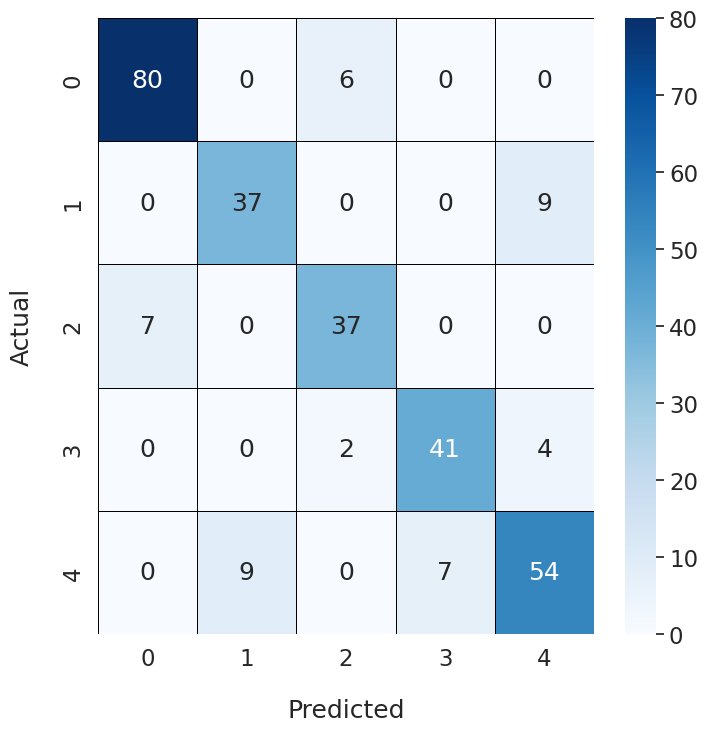

Epoch Training Time: 2195.53 seconds
Test set: Average loss: 0.4721, Accuracy: 255/323 (78.95%), F1 Score: 0.7848

Fold 3
-------
Early stopping at epoch 149 due to no improvement in validation loss.


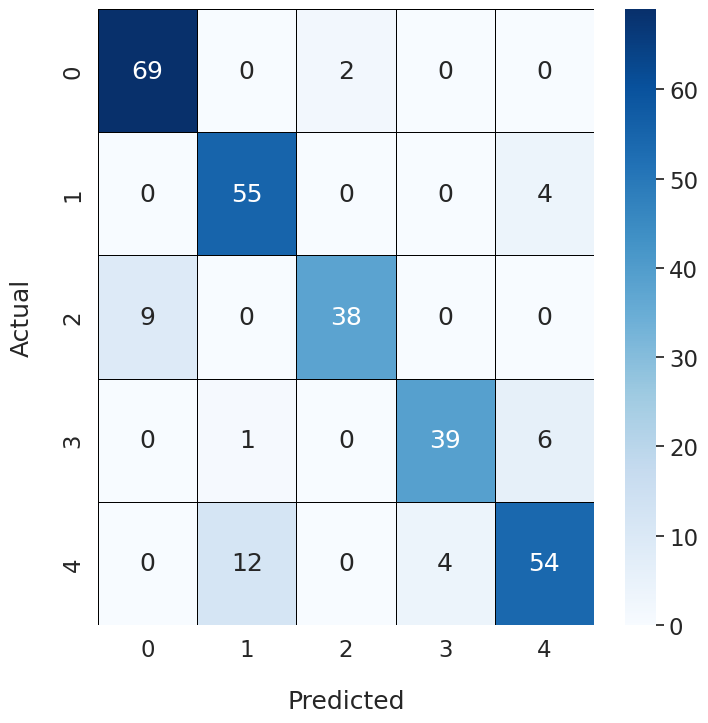

Epoch Training Time: 1879.22 seconds
Test set: Average loss: 0.4398, Accuracy: 266/323 (82.35%), F1 Score: 0.8216

Fold 4
-------
Early stopping at epoch 178 due to no improvement in validation loss.


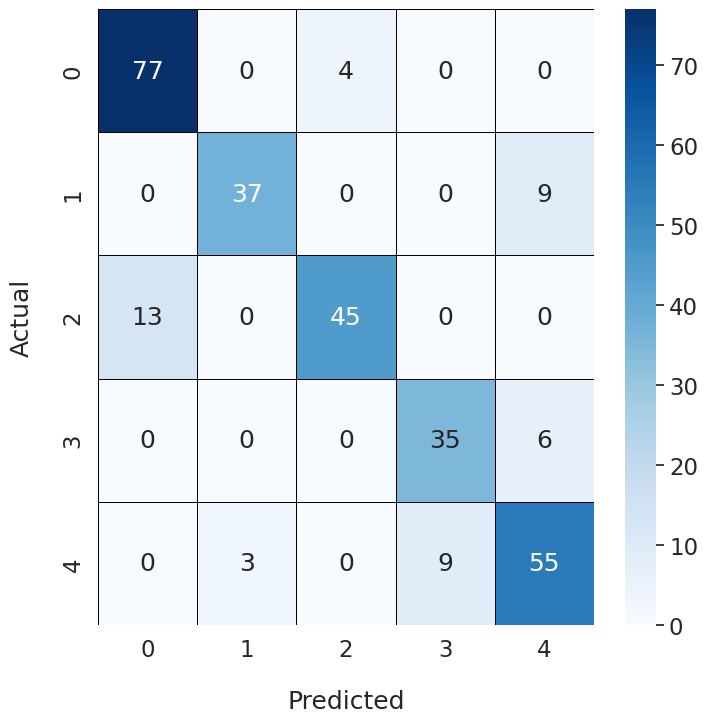

Epoch Training Time: 2433.89 seconds
Test set: Average loss: 0.5035, Accuracy: 261/323 (80.80%), F1 Score: 0.8070

Fold 5
-------
Early stopping at epoch 150 due to no improvement in validation loss.


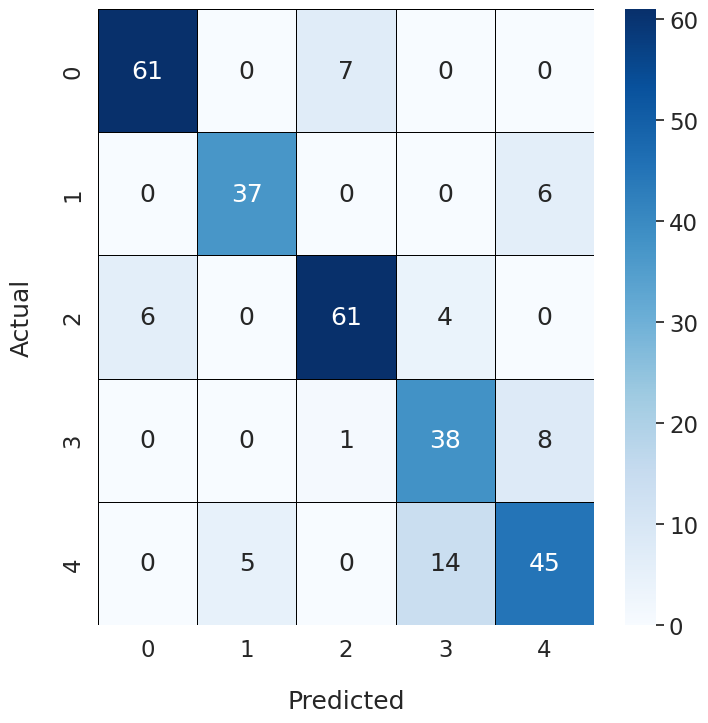

Epoch Training Time: 2117.01 seconds
Test set: Average loss: 0.4987, Accuracy: 260/323 (80.50%), F1 Score: 0.7986

Fold 6
-------
Early stopping at epoch 161 due to no improvement in validation loss.


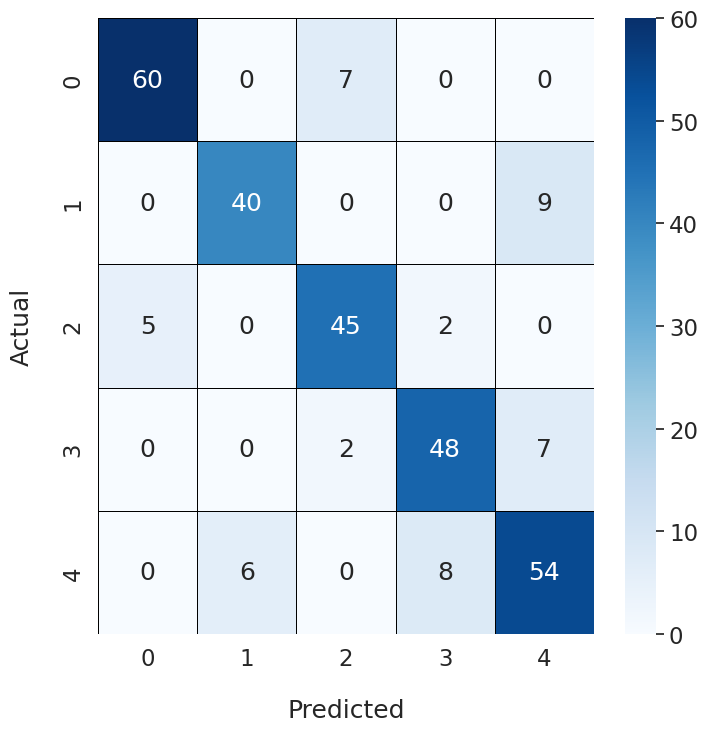

Epoch Training Time: 2122.56 seconds
Test set: Average loss: 0.4185, Accuracy: 272/323 (84.21%), F1 Score: 0.8409

Fold 7
-------
Early stopping at epoch 170 due to no improvement in validation loss.


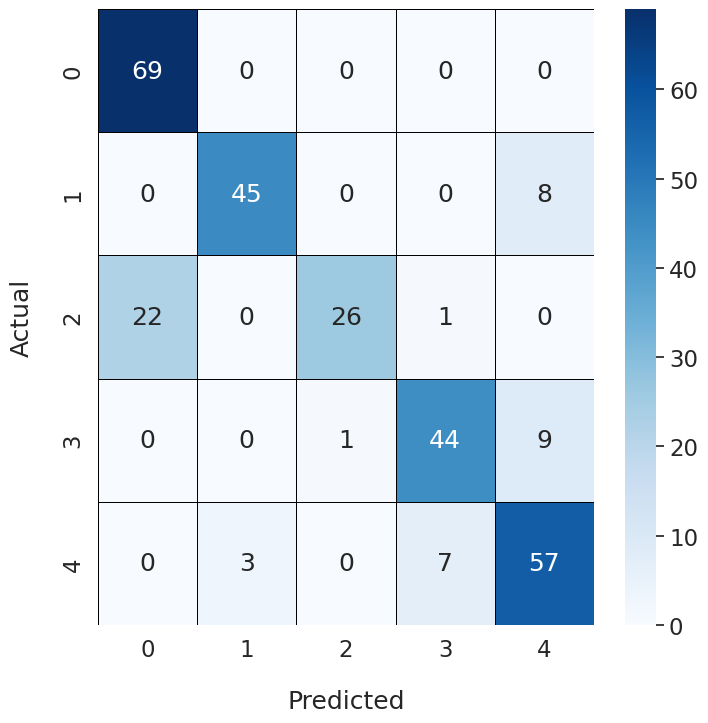

Epoch Training Time: 2152.95 seconds
Test set: Average loss: 0.4634, Accuracy: 259/323 (80.19%), F1 Score: 0.8006

Fold 8
-------
Early stopping at epoch 151 due to no improvement in validation loss.


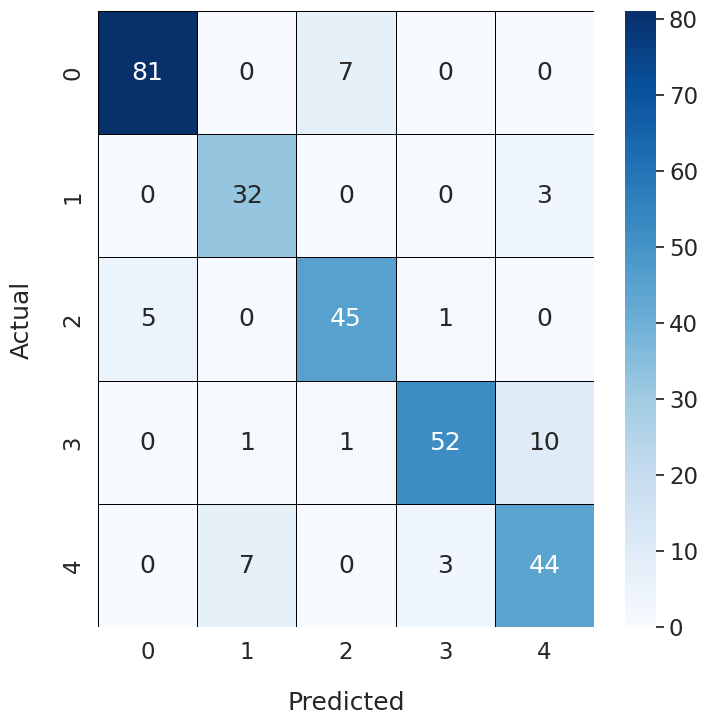

Epoch Training Time: 1993.31 seconds
Test set: Average loss: 0.4348, Accuracy: 267/323 (82.66%), F1 Score: 0.8253

Fold 9
-------
Early stopping at epoch 167 due to no improvement in validation loss.


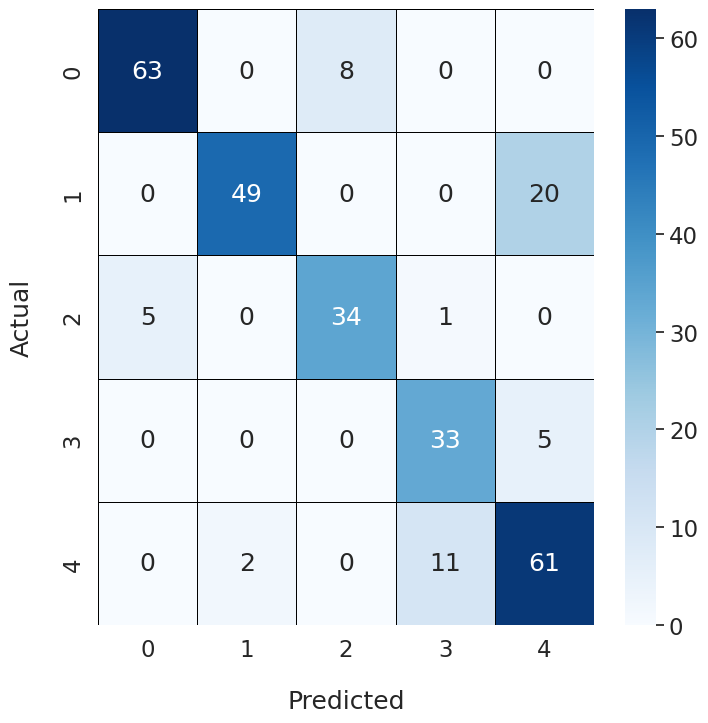

Epoch Training Time: 2016.35 seconds
Test set: Average loss: 0.4869, Accuracy: 259/323 (80.19%), F1 Score: 0.7985

Fold 10
-------
Early stopping at epoch 149 due to no improvement in validation loss.


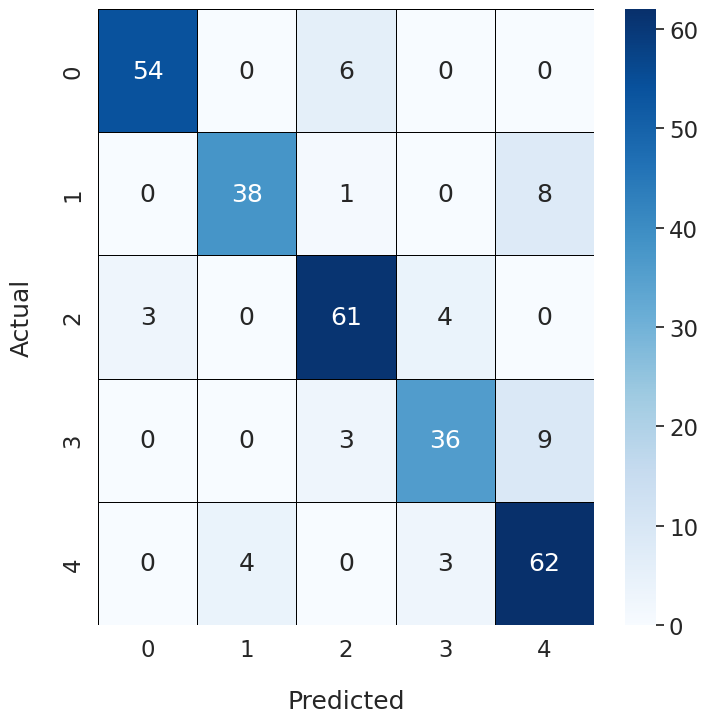

Epoch Training Time: 1934.11 seconds
Test set: Average loss: 0.4145, Accuracy: 268/323 (82.97%), F1 Score: 0.8285


Total training time for 10 folds: 20717.89 seconds


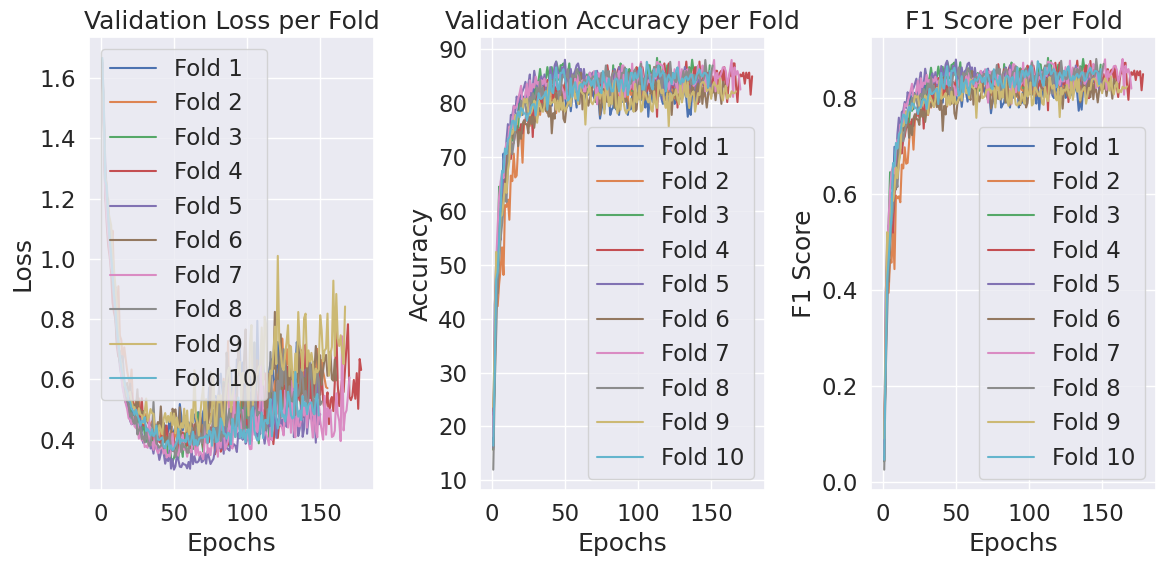

Maximum Fold Accuracy = 84.21052631578948
Maximum Fold F1 Score = 0.8408745882615962
Average Fold Accuracy = 81.42414860681114
Average Fold F1 Score = 0.8120436082326539


In [31]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "/home/gpu1/Desktop/rut_ws/Restnet101/result_Restnet/SE_fuzz"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/SE_fuzz/best_SE_fuzz.pth"
os.makedirs("./model_Restnet/SE_fuzz", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_SEfuzz.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_SEfuzz(ResidualBlock_SEfuzz, [3, 4, 23, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
          
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEfuzz_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet_SEfuzz(ResidualBlock_SEfuzz, [3, 4, 23, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [32]:
clear_all_memory()

Memory cleared and environment reset!


==========================================STAGE2===============================================================================================

Max Pool ResNet101-------------------------------------------------------------------------------------

In [1]:
import import_ipynb
from starter_restnet import *
import sys

Classes: 
['0- Ripe 100- Unripe', '100- Ripe 0- Unripe', '30- Ripe 70- Unripe', '50- Ripe 50- Unripe', '70- Ripe 30- Unripe']
Number of splits: 10


In [2]:
class ResidualBlock(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None):
            super(ResidualBlock, self).__init__()
            
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 1, stride = stride, padding = 0),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv3 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels*4, kernel_size = 1, stride = 1, padding = 0),
                            nn.BatchNorm2d(out_channels*4))
                           
            
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            out = self.conv3(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.maxpool2 = nn.AdaptiveMaxPool2d((1, 1))
            self.fc = nn.Linear(2048, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes*4:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes*4, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes*4),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes*4
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.maxpool2(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [3]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 9.99 GMac
Model Params: 42.56 M
Early stopping at epoch 142 due to no improvement in validation loss.


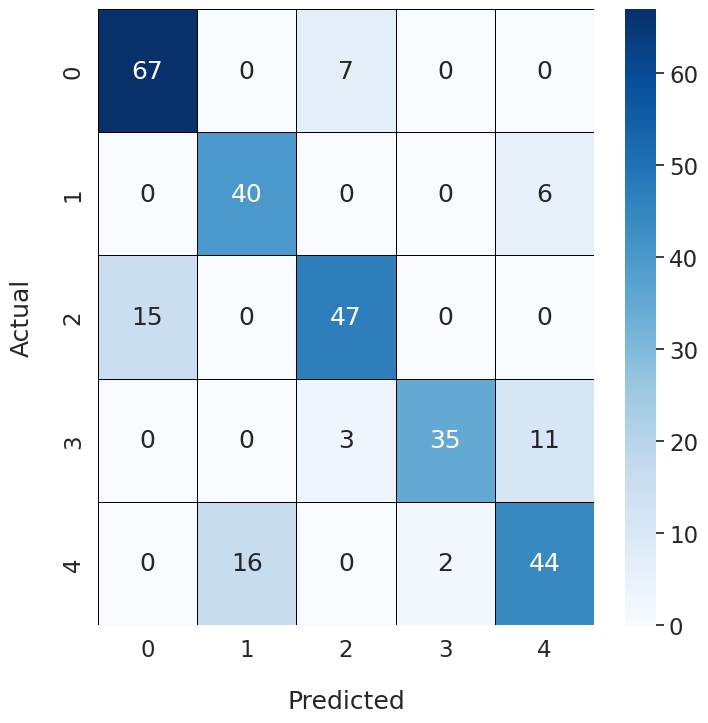

Epoch Training Time: 1587.62 seconds
Test set: Average loss: 0.4888, Accuracy: 260/323 (80.50%), F1 Score: 0.8047

Fold 2
-------
Early stopping at epoch 140 due to no improvement in validation loss.


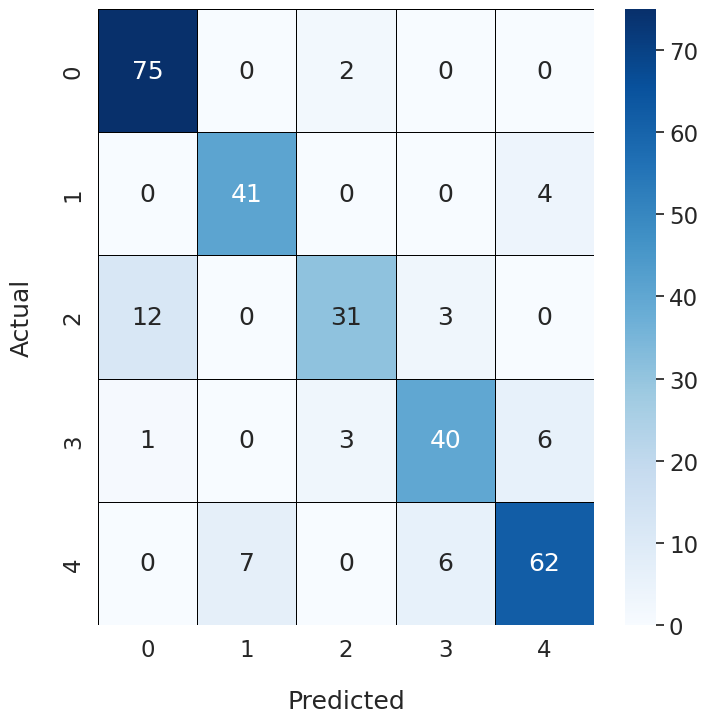

Epoch Training Time: 1567.07 seconds
Test set: Average loss: 0.4529, Accuracy: 260/323 (80.50%), F1 Score: 0.8033

Fold 3
-------
Early stopping at epoch 153 due to no improvement in validation loss.


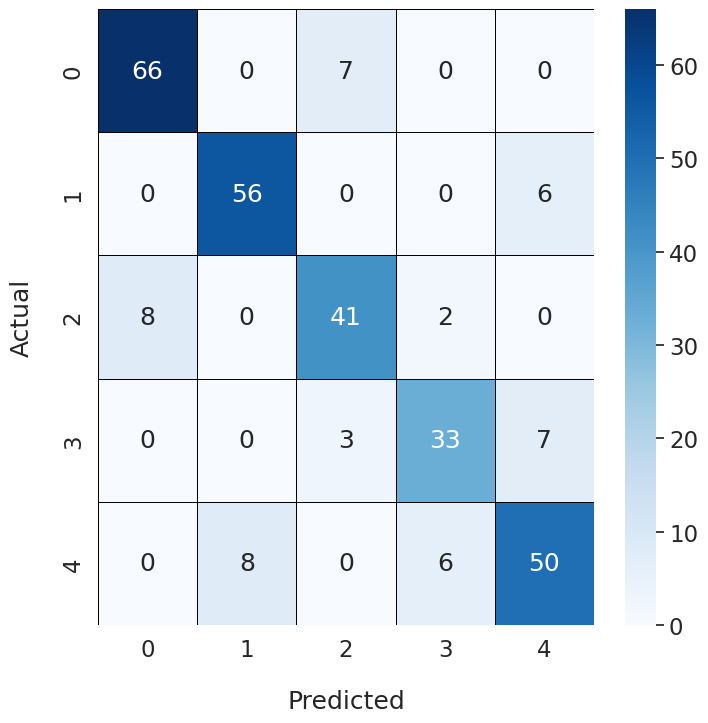

Epoch Training Time: 1713.61 seconds
Test set: Average loss: 0.5368, Accuracy: 255/323 (78.95%), F1 Score: 0.7894

Fold 4
-------
Early stopping at epoch 142 due to no improvement in validation loss.


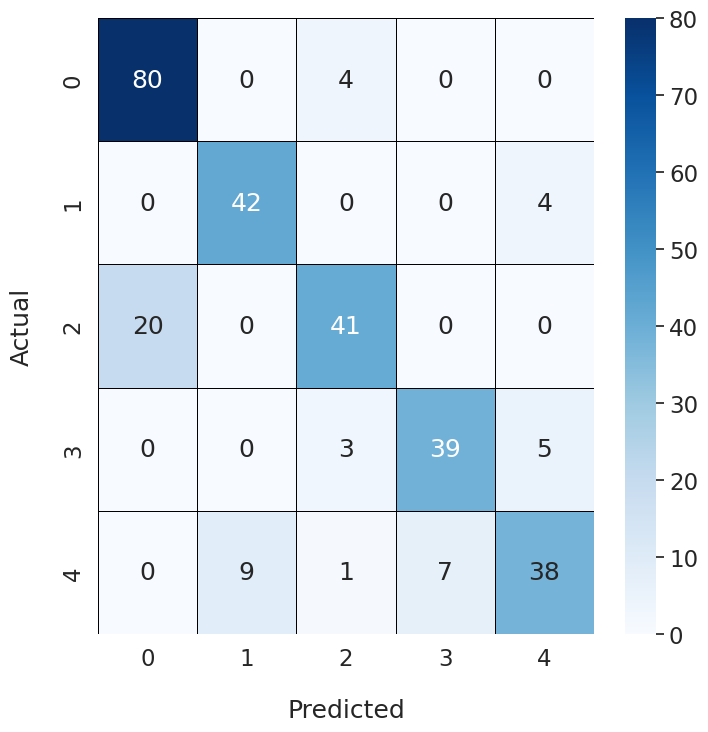

Epoch Training Time: 1589.52 seconds
Test set: Average loss: 0.5234, Accuracy: 260/323 (80.50%), F1 Score: 0.8006

Fold 5
-------
Early stopping at epoch 150 due to no improvement in validation loss.


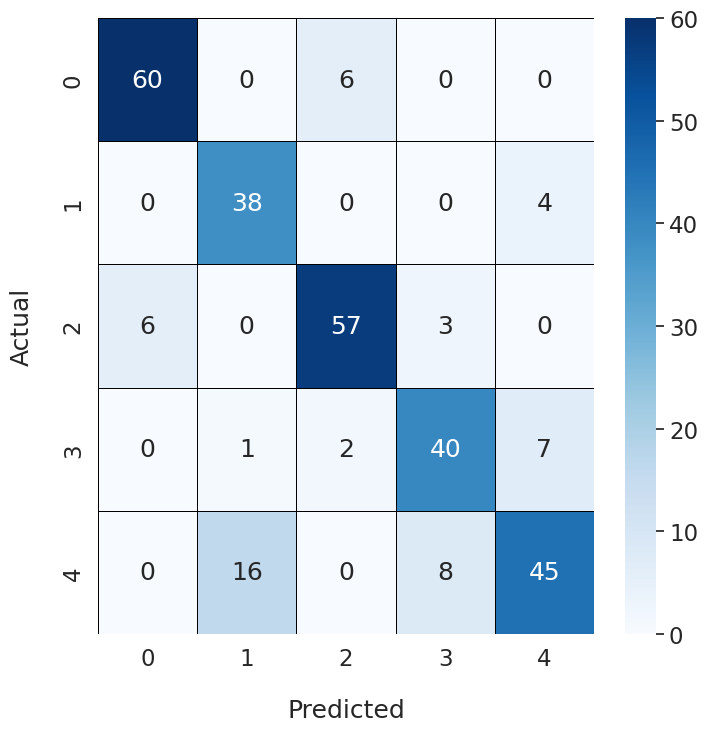

Epoch Training Time: 1677.15 seconds
Test set: Average loss: 0.5382, Accuracy: 265/323 (82.04%), F1 Score: 0.8197

Fold 6
-------
Early stopping at epoch 153 due to no improvement in validation loss.


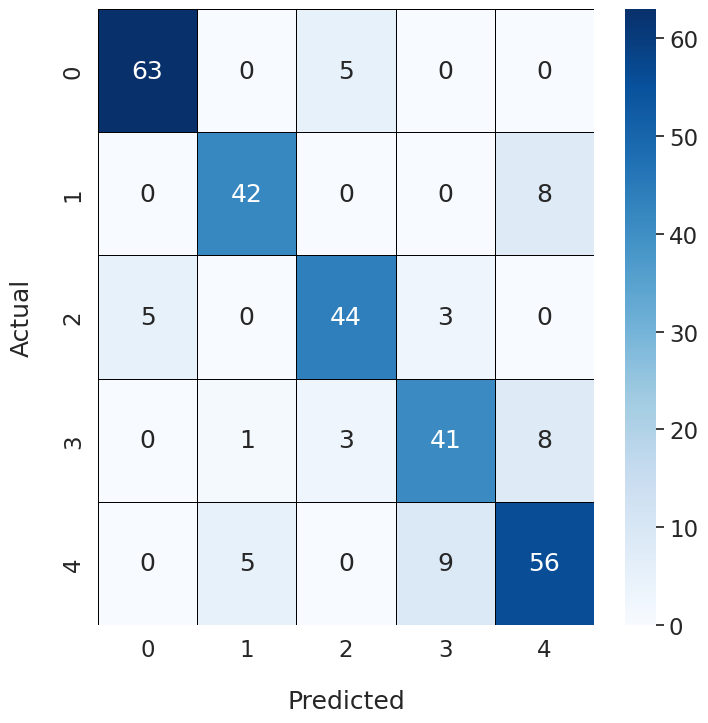

Epoch Training Time: 1710.79 seconds
Test set: Average loss: 0.5737, Accuracy: 257/323 (79.57%), F1 Score: 0.7933

Fold 7
-------
Early stopping at epoch 186 due to no improvement in validation loss.


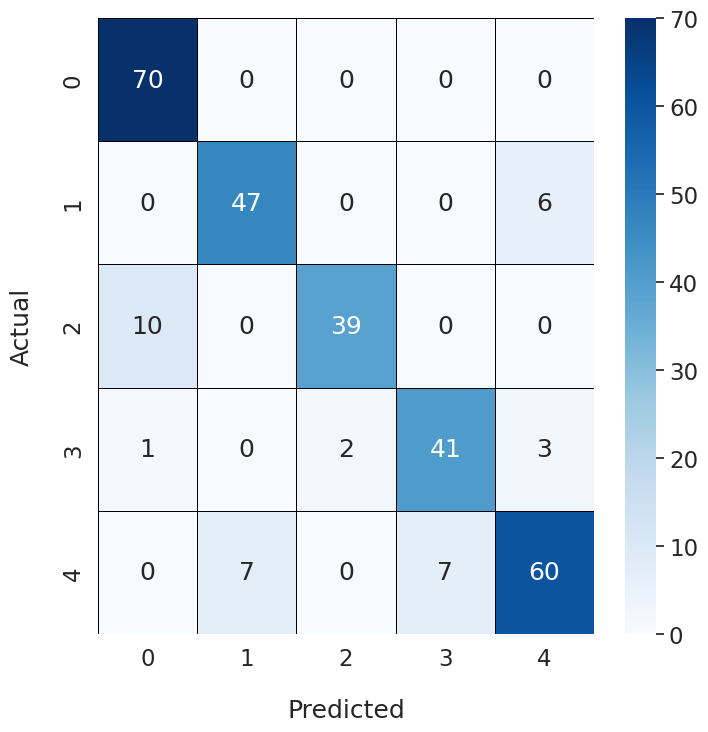

Epoch Training Time: 2080.57 seconds
Test set: Average loss: 0.5515, Accuracy: 265/323 (82.04%), F1 Score: 0.8180

Fold 8
-------
Early stopping at epoch 180 due to no improvement in validation loss.


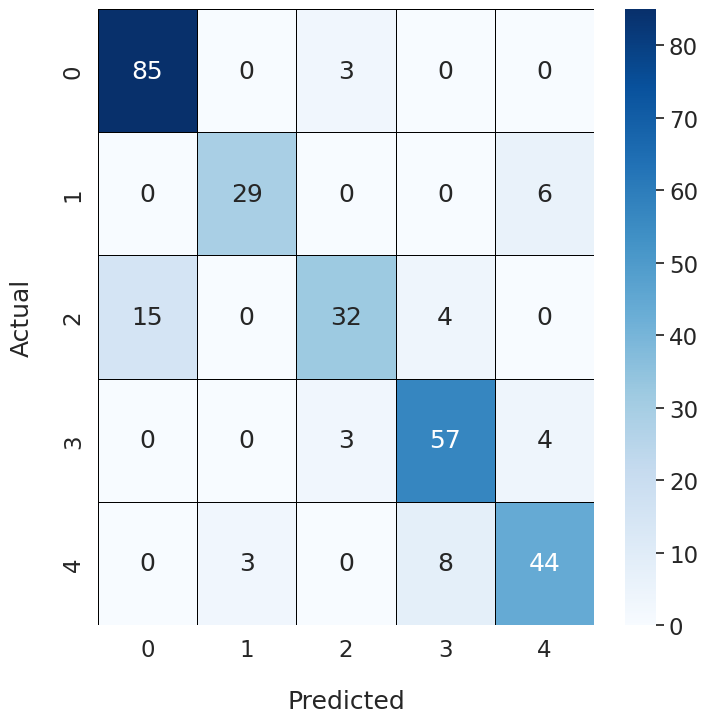

Epoch Training Time: 2014.49 seconds
Test set: Average loss: 0.5129, Accuracy: 261/323 (80.80%), F1 Score: 0.8056

Fold 9
-------
Early stopping at epoch 193 due to no improvement in validation loss.


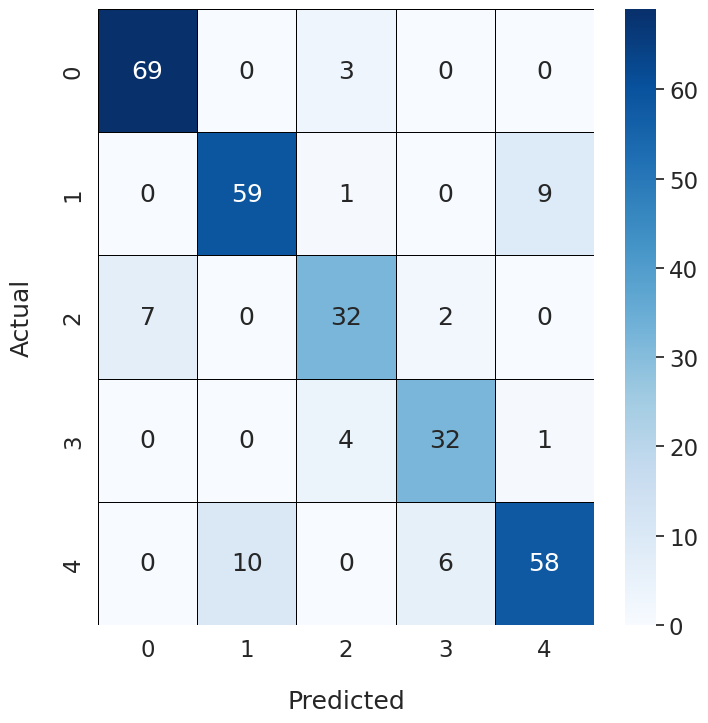

Epoch Training Time: 2157.97 seconds
Test set: Average loss: 0.5593, Accuracy: 264/323 (81.73%), F1 Score: 0.8142

Fold 10
-------
Early stopping at epoch 139 due to no improvement in validation loss.


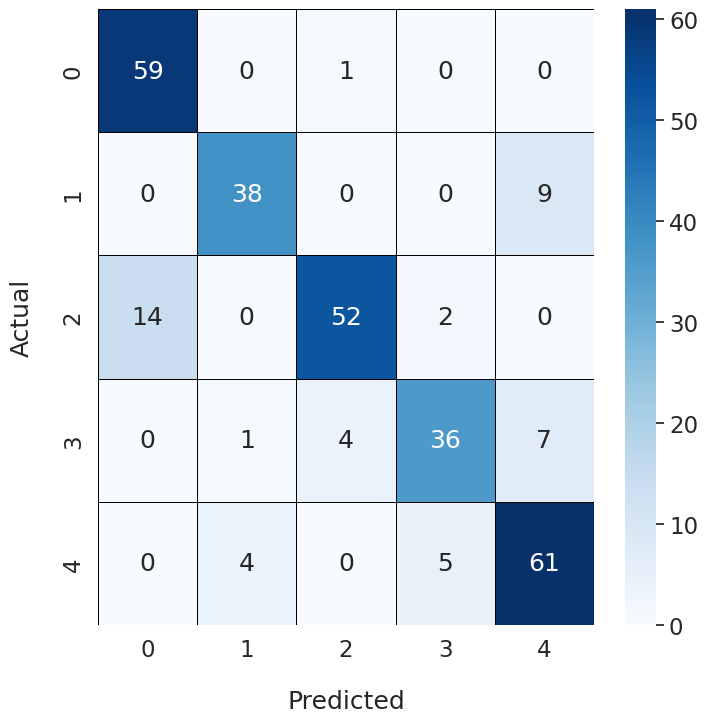

Epoch Training Time: 1554.79 seconds
Test set: Average loss: 0.4924, Accuracy: 255/323 (78.95%), F1 Score: 0.7874


Total training time for 10 folds: 17653.57 seconds


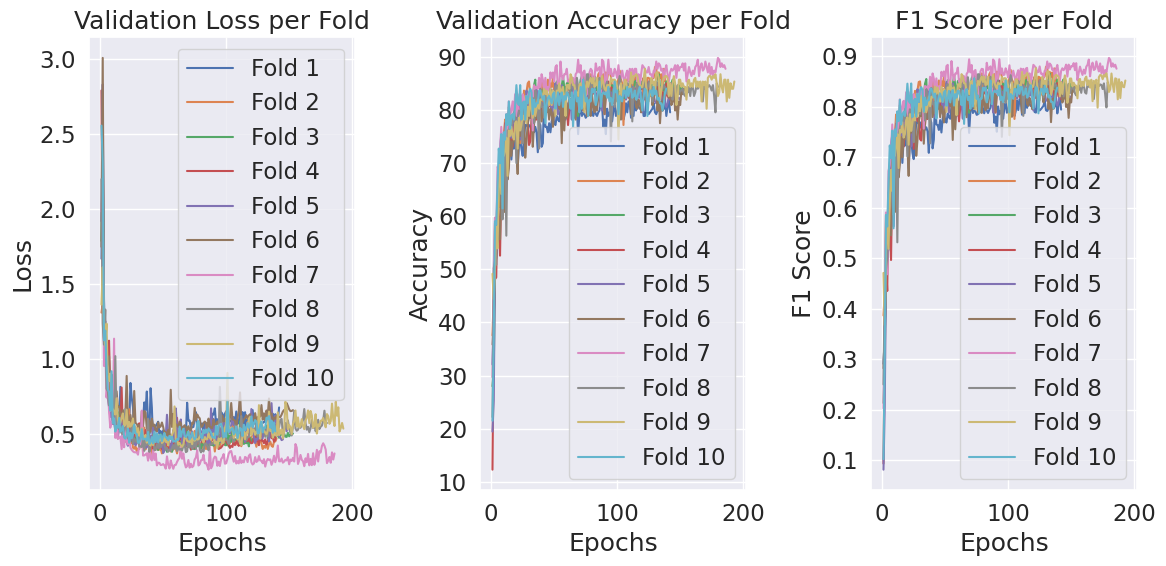

Maximum Fold Accuracy = 82.04334365325077
Maximum Fold F1 Score = 0.8196733257110157
Average Fold Accuracy = 80.55727554179568
Average Fold F1 Score = 0.8036249777556392


In [4]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "/home/rut/Desktop/KMUTNB_wrok/pytorch_cnn/Restnets/Restnet101/result_Restnet/MaxPool_ResNet"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/MaxPool_ResNet/MaxPool_ResNet.pth"
os.makedirs("./model_Restnet/MaxPool_ResNet", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_MaxPool_ResNet.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet(ResidualBlock, [3, 4, 23, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
          
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEmix_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet(ResidualBlock, [3, 4, 23, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [37]:
clear_all_memory()

Memory cleared and environment reset!


Mix Pool ResNet101-------------------------------------------------------------------------------------

In [38]:
from Mixedpool05 import mixedPool

In [39]:
import import_ipynb
from starter_restnet import *
import sys

In [40]:
class ResidualBlock(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None):
            super(ResidualBlock, self).__init__()
            
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 1, stride = stride, padding = 0),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv3 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels*4, kernel_size = 1, stride = 1, padding = 0),
                            nn.BatchNorm2d(out_channels*4))
                           
            
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            out = self.conv3(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.mixed_pool = mixedPool()
            self.fc = nn.Linear(2048, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes*4:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes*4, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes*4),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes*4
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.mixed_pool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [41]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 9.99 GMac
Model Params: 42.56 M
Early stopping at epoch 150 due to no improvement in validation loss.


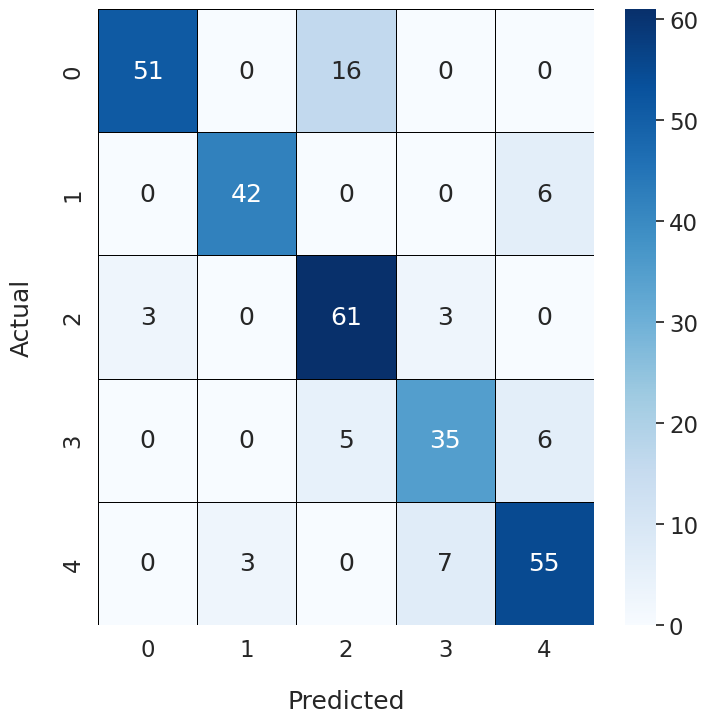

Epoch Training Time: 1326.08 seconds
Test set: Average loss: 0.4832, Accuracy: 266/323 (82.35%), F1 Score: 0.8211

Fold 2
-------
Early stopping at epoch 160 due to no improvement in validation loss.


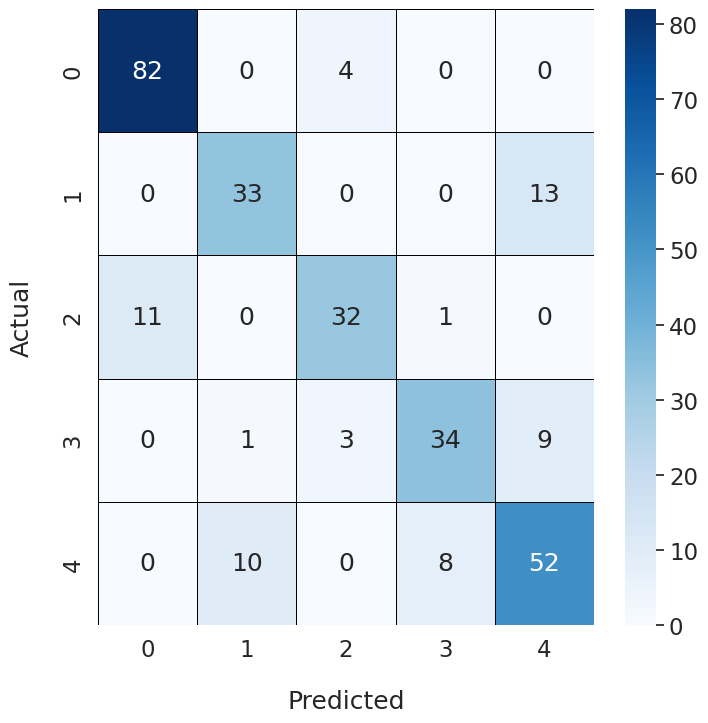

Epoch Training Time: 1325.55 seconds
Test set: Average loss: 0.5163, Accuracy: 259/323 (80.19%), F1 Score: 0.8012

Fold 3
-------
Early stopping at epoch 175 due to no improvement in validation loss.


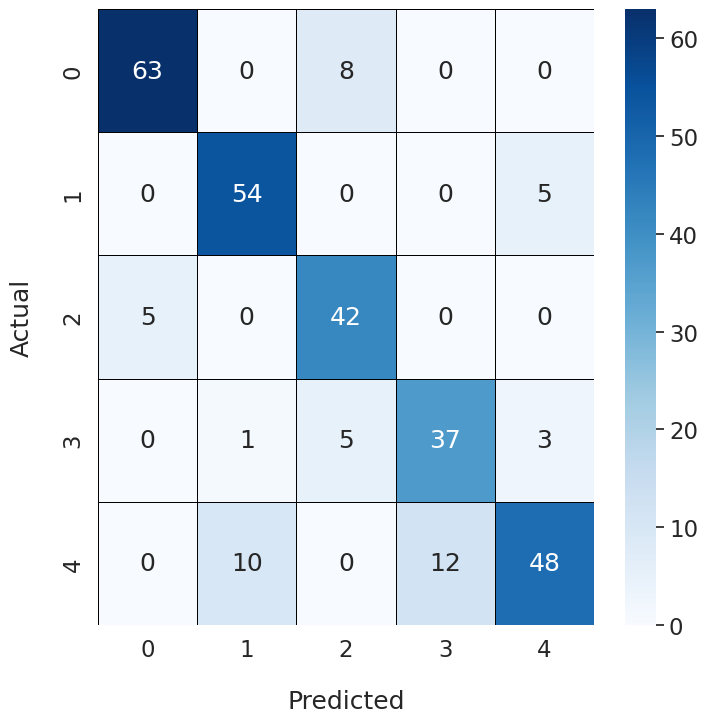

Epoch Training Time: 1576.43 seconds
Test set: Average loss: 0.5547, Accuracy: 265/323 (82.04%), F1 Score: 0.8184

Fold 4
-------
Early stopping at epoch 162 due to no improvement in validation loss.


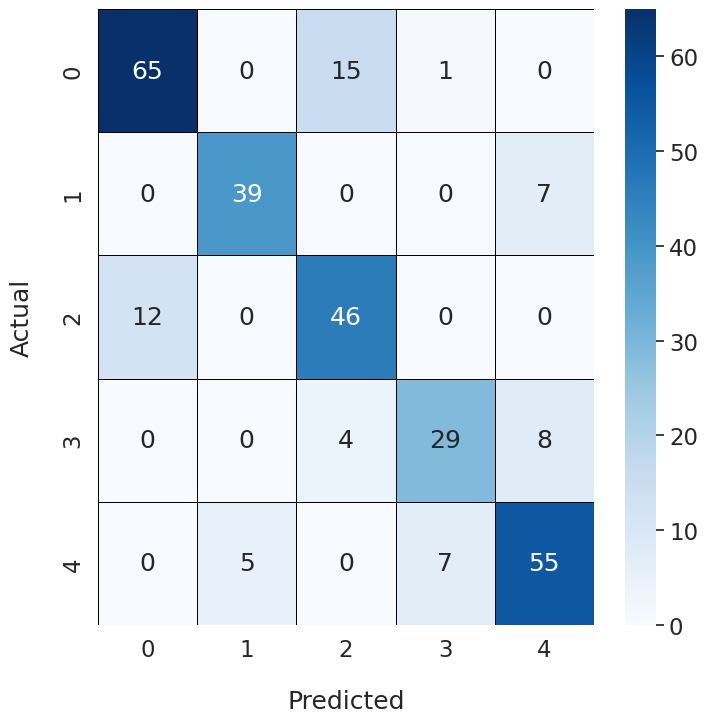

Epoch Training Time: 1610.66 seconds
Test set: Average loss: 0.4692, Accuracy: 260/323 (80.50%), F1 Score: 0.8039

Fold 5
-------
Early stopping at epoch 174 due to no improvement in validation loss.


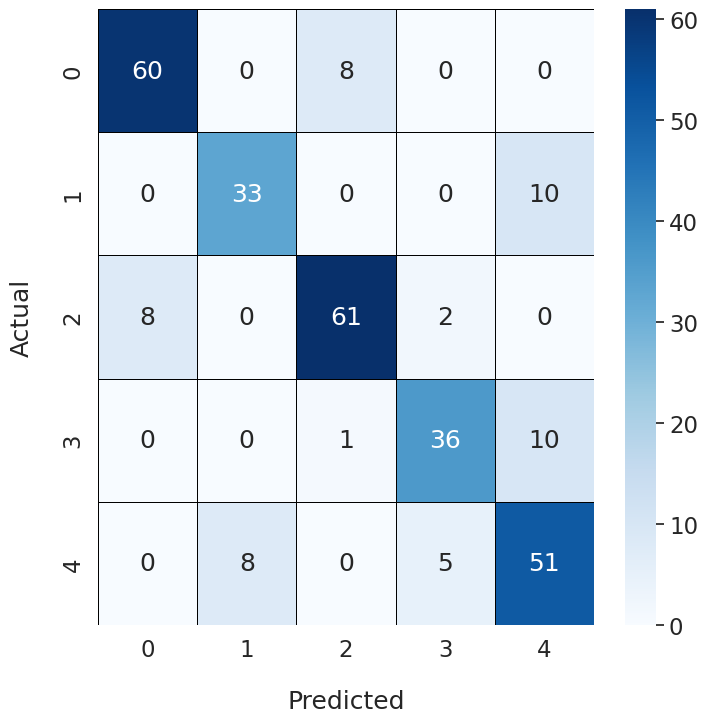

Epoch Training Time: 1591.80 seconds
Test set: Average loss: 0.5098, Accuracy: 267/323 (82.66%), F1 Score: 0.8253

Fold 6
-------
Early stopping at epoch 156 due to no improvement in validation loss.


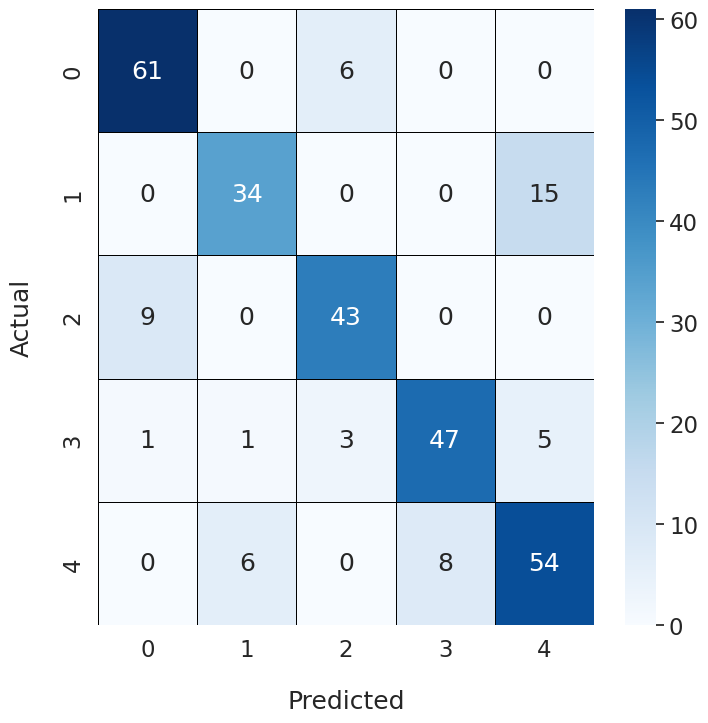

Epoch Training Time: 1592.02 seconds
Test set: Average loss: 0.4691, Accuracy: 260/323 (80.50%), F1 Score: 0.8044

Fold 7
-------
Early stopping at epoch 185 due to no improvement in validation loss.


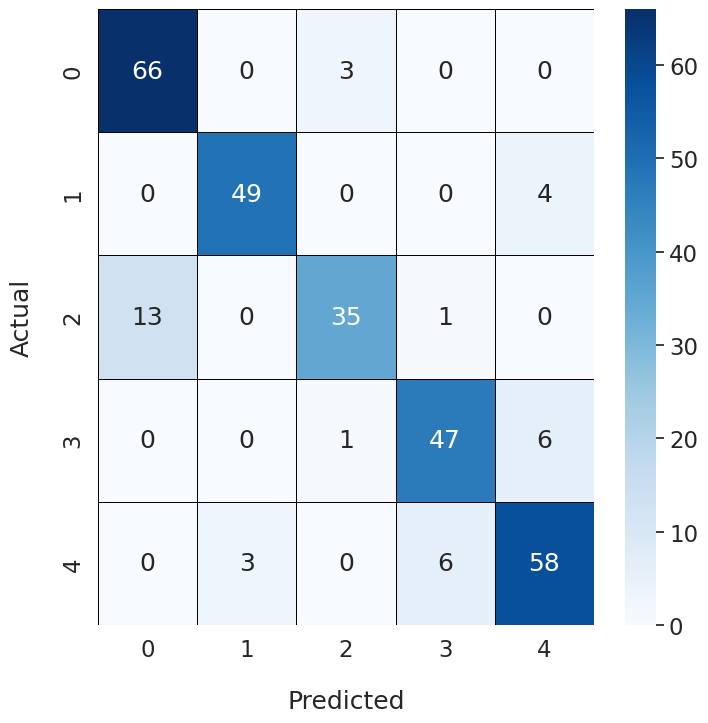

Epoch Training Time: 1727.51 seconds
Test set: Average loss: 0.5401, Accuracy: 264/323 (81.73%), F1 Score: 0.8157

Fold 8
-------
Early stopping at epoch 186 due to no improvement in validation loss.


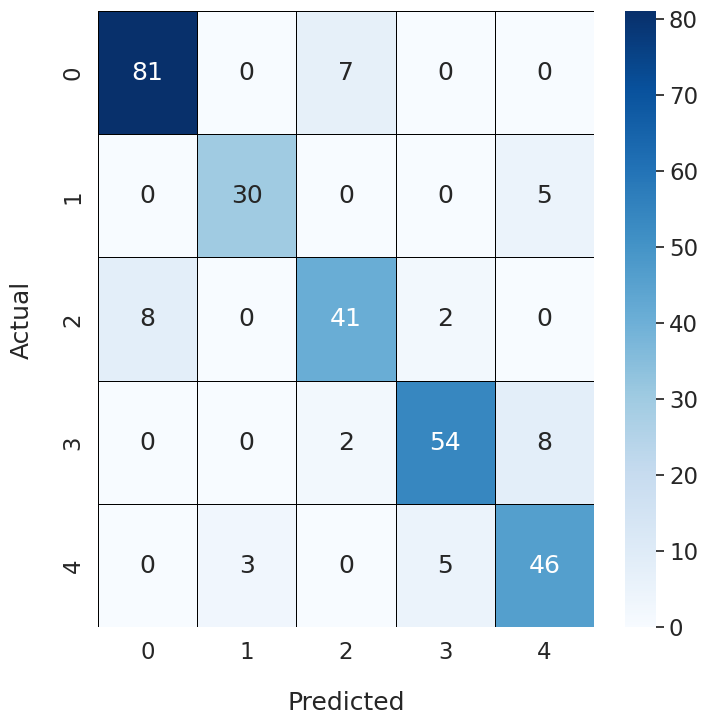

Epoch Training Time: 1872.39 seconds
Test set: Average loss: 0.6223, Accuracy: 249/323 (77.09%), F1 Score: 0.7680

Fold 9
-------
Early stopping at epoch 157 due to no improvement in validation loss.


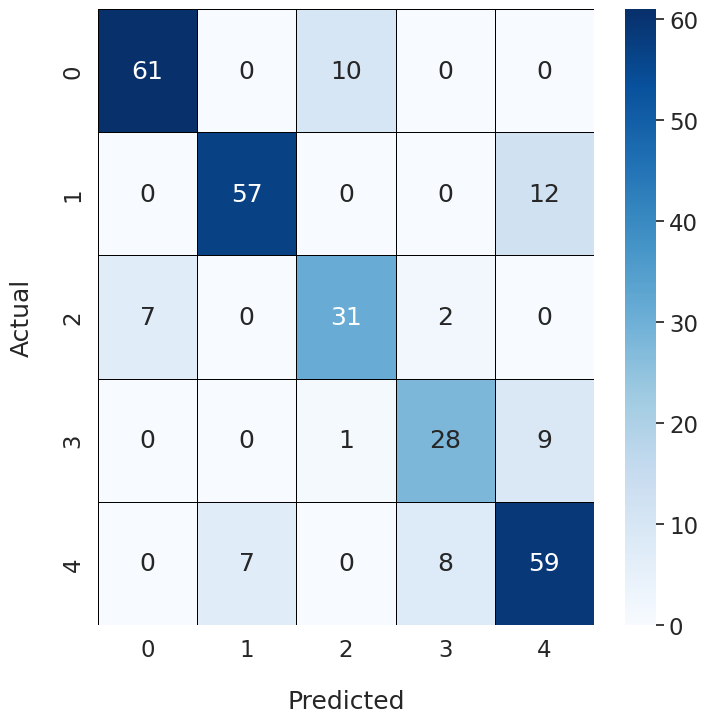

Epoch Training Time: 1571.80 seconds
Test set: Average loss: 0.4772, Accuracy: 263/323 (81.42%), F1 Score: 0.8133

Fold 10
-------
Early stopping at epoch 148 due to no improvement in validation loss.


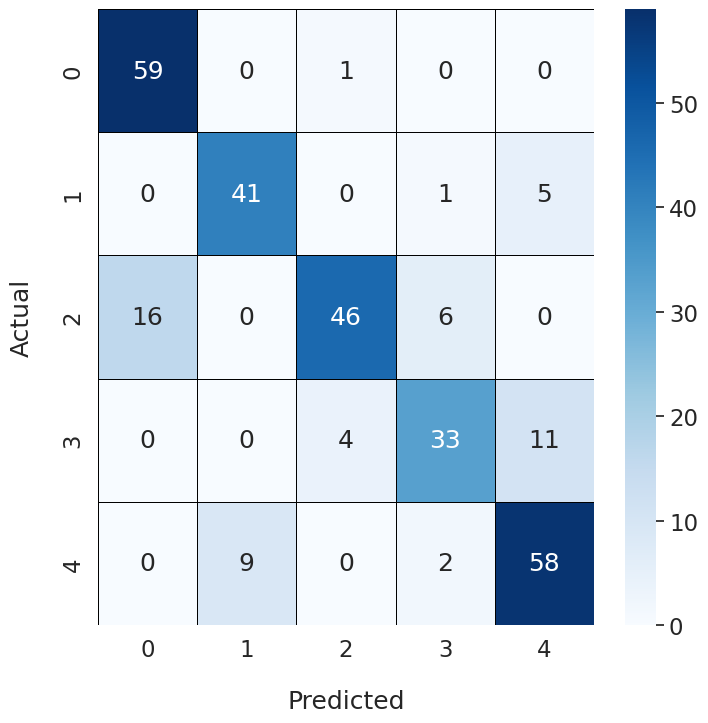

Epoch Training Time: 1283.99 seconds
Test set: Average loss: 0.4110, Accuracy: 267/323 (82.66%), F1 Score: 0.8260


Total training time for 10 folds: 15478.23 seconds


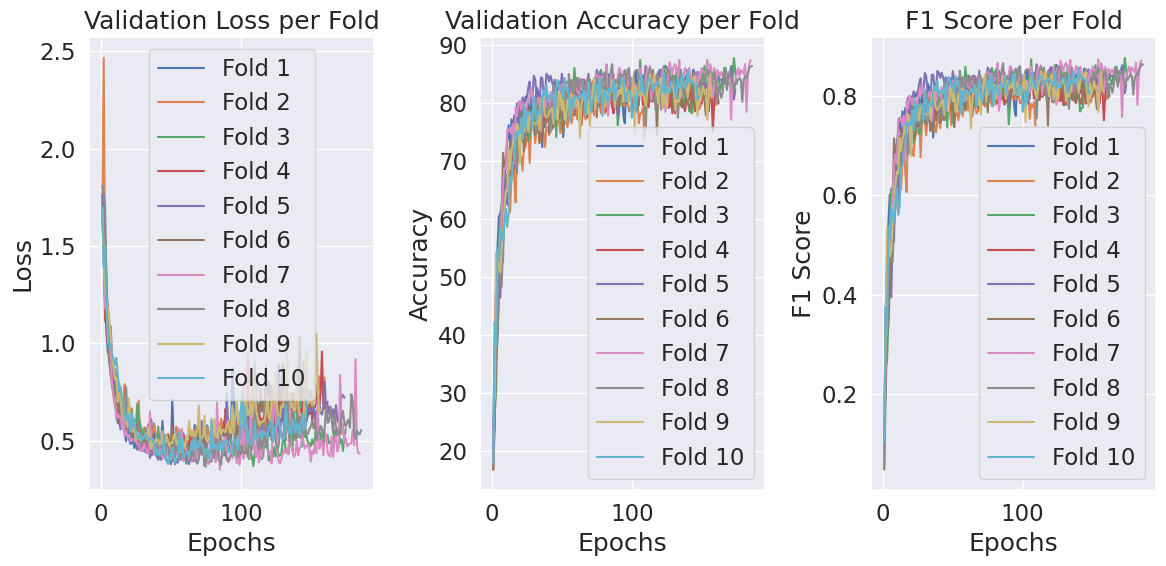

Maximum Fold Accuracy = 82.6625386996904
Maximum Fold F1 Score = 0.825950557646964
Average Fold Accuracy = 81.11455108359135
Average Fold F1 Score = 0.8097304514656061


In [42]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "/home/gpu1/Desktop/rut_ws/Restnet101/result_Restnet/MixPool_ResNet"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/MixPool_ResNet/MixPool_ResNet.pth"
os.makedirs("./model_Restnet/MixPool_ResNet", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_MixPool_ResNet.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet(ResidualBlock, [3, 4, 23, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
          
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEmix_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet(ResidualBlock, [3, 4, 23, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [43]:
clear_all_memory()

Memory cleared and environment reset!


FuzzyPool RenNet101-------------------------------------------------------------------------------------------------------

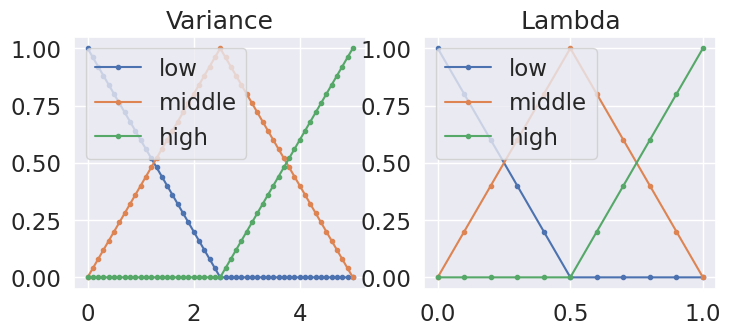

fuzzy_pool_noSE


In [44]:
from Mixedpool_fuzzy_noSE import mixedPool_fuzz

In [45]:
import import_ipynb
from starter_restnet import *
import sys

In [46]:
class ResidualBlock(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None):
            super(ResidualBlock, self).__init__()
            
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 1, stride = stride, padding = 0),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv3 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels*4, kernel_size = 1, stride = 1, padding = 0),
                            nn.BatchNorm2d(out_channels*4))
                           
            
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            out = self.conv3(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.fuzz_pool = mixedPool_fuzz()
            self.fc = nn.Linear(2048, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes*4:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes*4, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes*4),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes*4
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.fuzz_pool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [47]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 9.99 GMac
Model Params: 42.56 M
Early stopping at epoch 198 due to no improvement in validation loss.


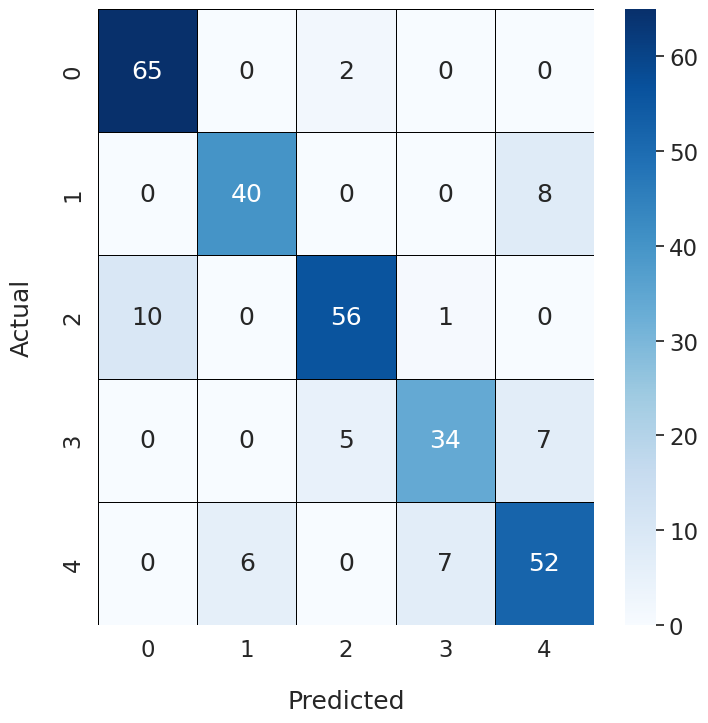

Epoch Training Time: 1862.12 seconds
Test set: Average loss: 0.5781, Accuracy: 265/323 (82.04%), F1 Score: 0.8201

Fold 2
-------
Early stopping at epoch 176 due to no improvement in validation loss.


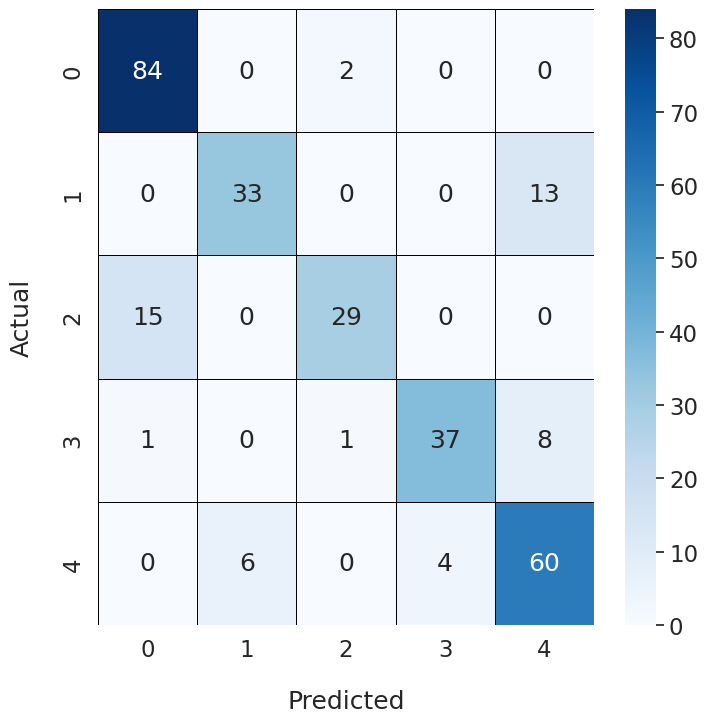

Epoch Training Time: 1720.61 seconds
Test set: Average loss: 0.5616, Accuracy: 262/323 (81.11%), F1 Score: 0.8108

Fold 3
-------
Early stopping at epoch 202 due to no improvement in validation loss.


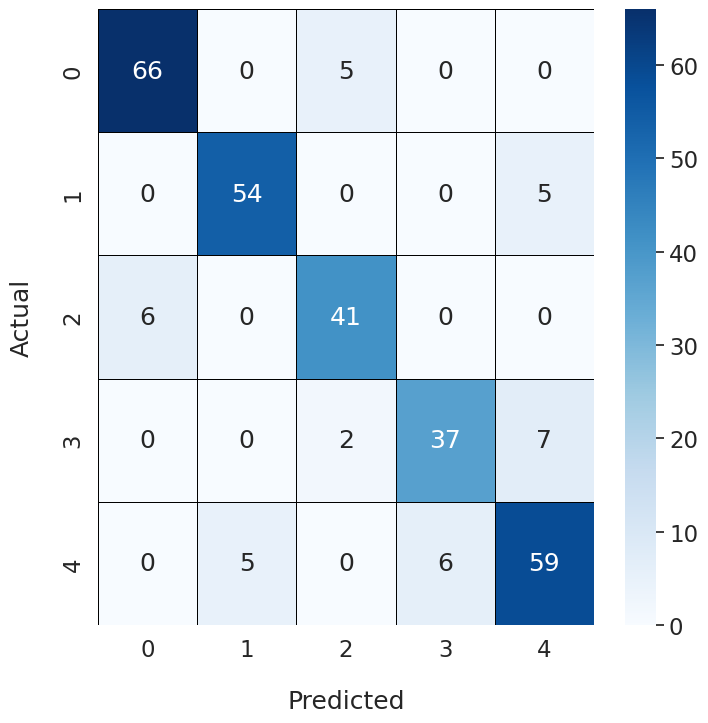

Epoch Training Time: 1976.02 seconds
Test set: Average loss: 0.4533, Accuracy: 268/323 (82.97%), F1 Score: 0.8289

Fold 4
-------
Early stopping at epoch 178 due to no improvement in validation loss.


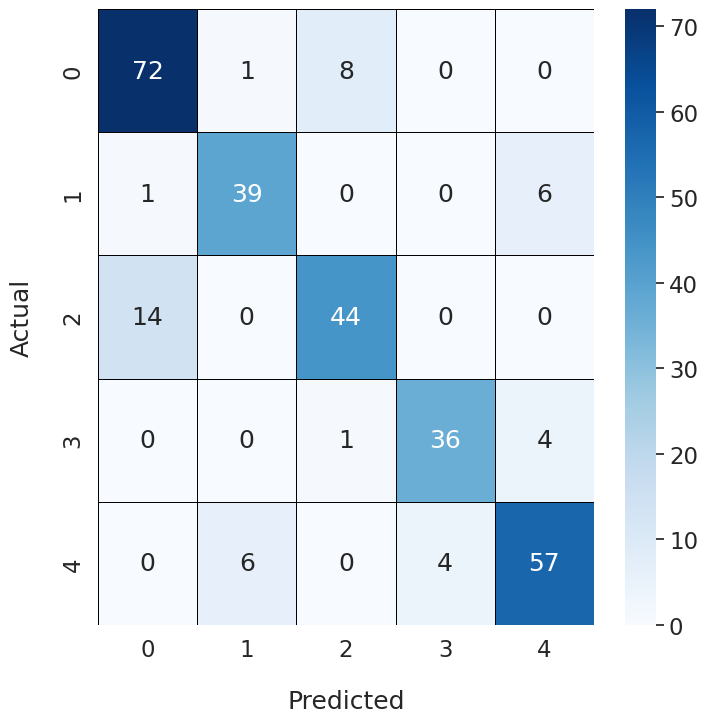

Epoch Training Time: 1729.76 seconds
Test set: Average loss: 0.7342, Accuracy: 274/323 (84.83%), F1 Score: 0.8464

Fold 5
-------
Early stopping at epoch 169 due to no improvement in validation loss.


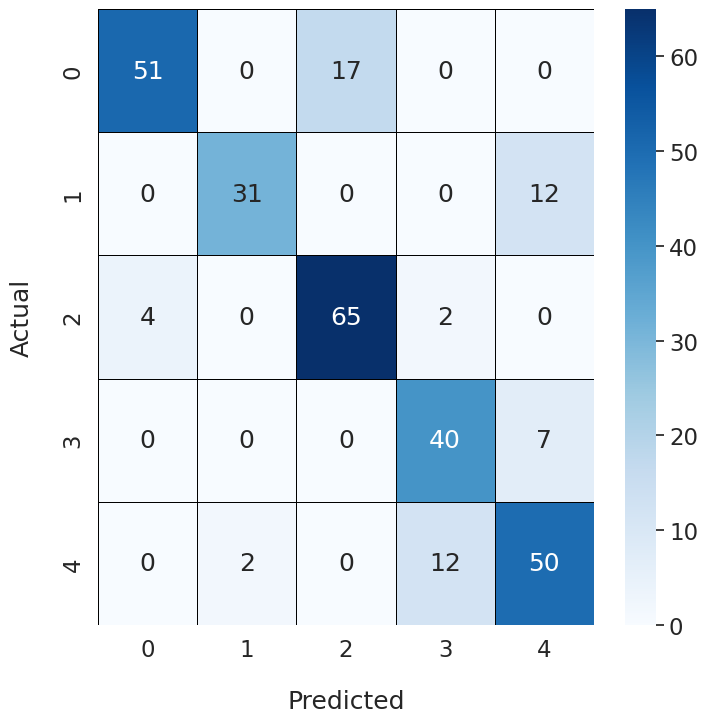

Epoch Training Time: 1700.73 seconds
Test set: Average loss: 0.4720, Accuracy: 267/323 (82.66%), F1 Score: 0.8250

Fold 6
-------
Early stopping at epoch 183 due to no improvement in validation loss.


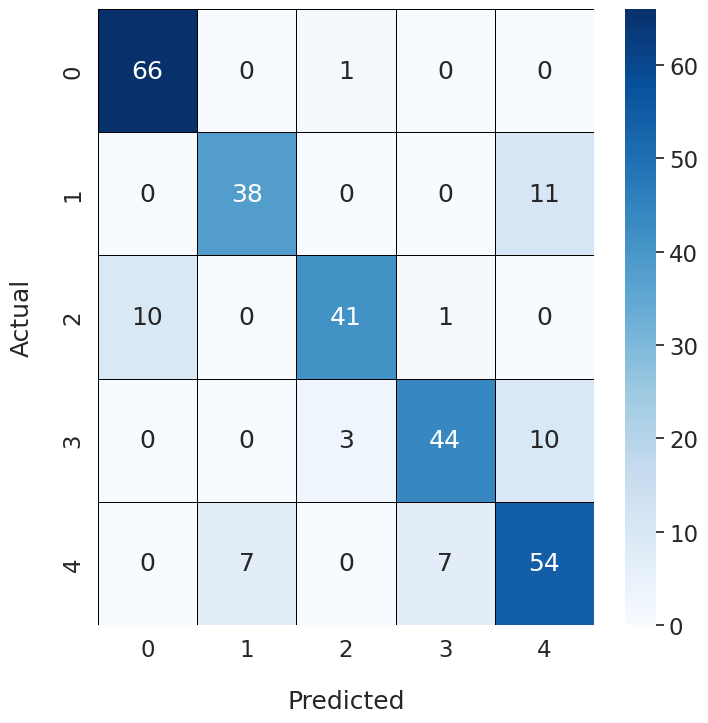

Epoch Training Time: 2052.51 seconds
Test set: Average loss: 0.5464, Accuracy: 266/323 (82.35%), F1 Score: 0.8219

Fold 7
-------
Early stopping at epoch 325 due to no improvement in validation loss.


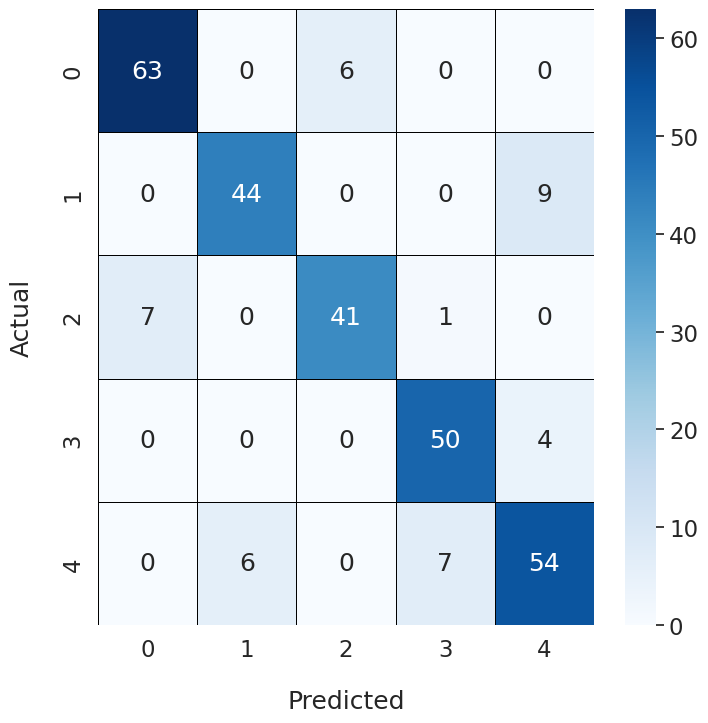

Epoch Training Time: 3139.36 seconds
Test set: Average loss: 0.7736, Accuracy: 264/323 (81.73%), F1 Score: 0.8148

Fold 8
-------
Early stopping at epoch 198 due to no improvement in validation loss.


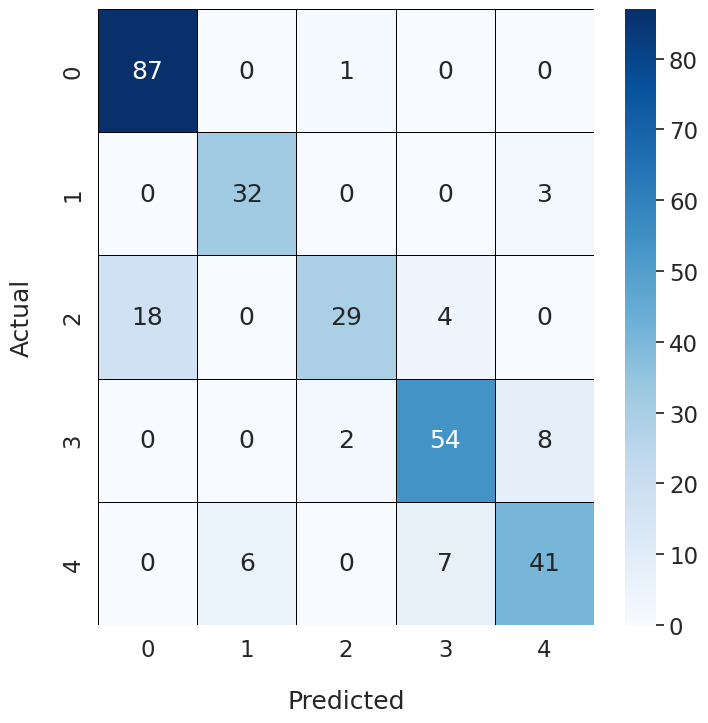

Epoch Training Time: 1995.43 seconds
Test set: Average loss: 0.5603, Accuracy: 278/323 (86.07%), F1 Score: 0.8592

Fold 9
-------
Early stopping at epoch 189 due to no improvement in validation loss.


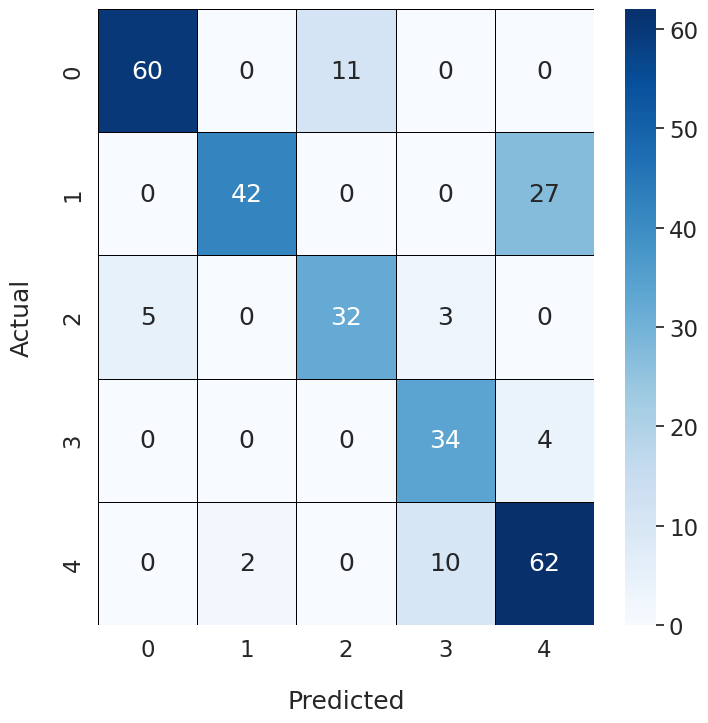

Epoch Training Time: 1788.05 seconds
Test set: Average loss: 0.5798, Accuracy: 264/323 (81.73%), F1 Score: 0.8148

Fold 10
-------
Early stopping at epoch 255 due to no improvement in validation loss.


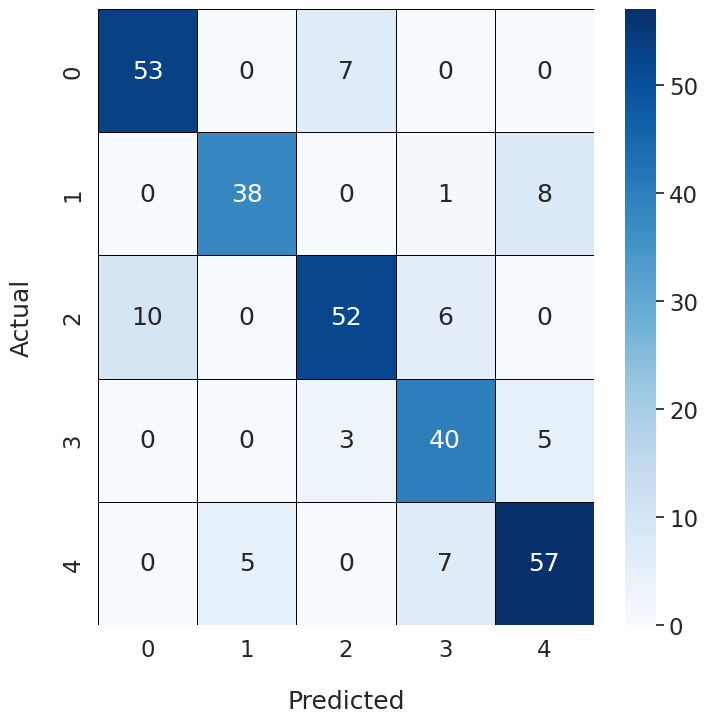

Epoch Training Time: 2467.88 seconds
Test set: Average loss: 0.6086, Accuracy: 272/323 (84.21%), F1 Score: 0.8422


Total training time for 10 folds: 20432.46 seconds


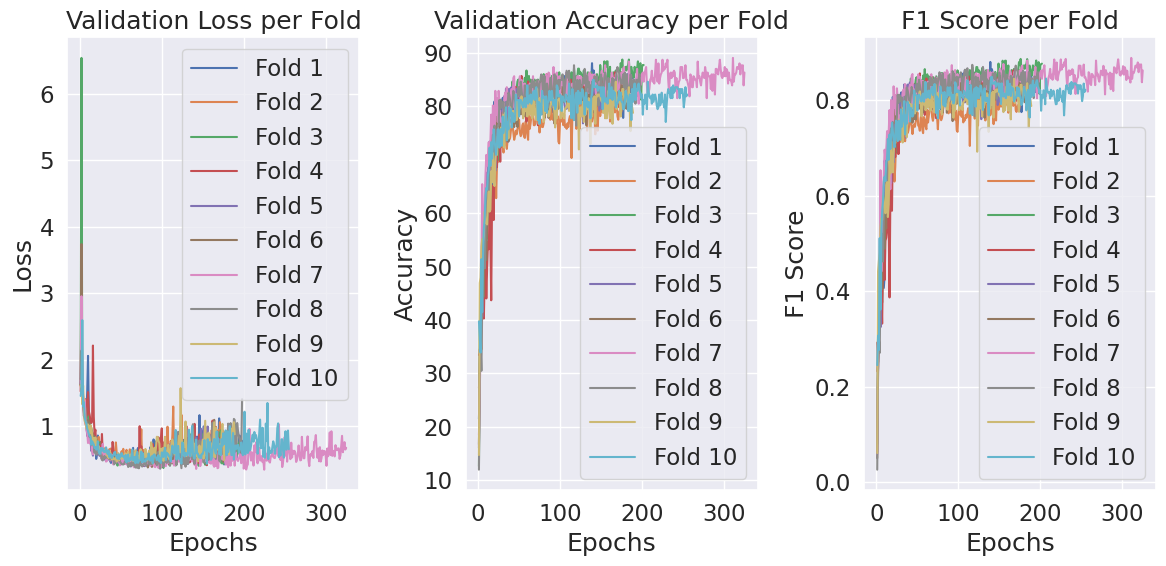

Maximum Fold Accuracy = 86.06811145510837
Maximum Fold F1 Score = 0.8591612652430682
Average Fold Accuracy = 82.97213622291022
Average Fold F1 Score = 0.8283826576286405


In [48]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "/home/gpu1/Desktop/rut_ws/Restnet101/result_Restnet/FuzzPool_ResNet"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/FuzzPool_ResNet/FuzzPool_ResNet.pth"
os.makedirs("./model_Restnet/FuzzPool_ResNet", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_FuzzPool_ResNet.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet(ResidualBlock, [3, 4, 23, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
          
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEmix_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet(ResidualBlock, [3, 4, 23, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [49]:
clear_all_memory()

Memory cleared and environment reset!
